# Scenario lab - transition levers for EMT Madrid

**IE Sustainability Datathon (Kearney) · supplementary notebook · not a deliverable**

This notebook tests transition strategies that the brief's two mandatory scenarios cannot express.
`File_4.csv` is fixed at **20 rows - 2026-2035 x scenario {0, 1}** and the final compliance cell in
notebook 01 asserts exactly that, so a third strategy can never live in the deliverable. Following the
README rule - *supplementary analyses are printed in the notebook, never written into `File_1-4.csv`* -
everything here stays on screen.

**The question.** EMT runs 1,748 CNG buses at a mean age of 6.6 years. Reaching 100% zero-emission
means retiring most of them long before the end of their life. **Retrofitting** a CNG bus to
battery-electric keeps the vehicle and replaces the driveline. Where is that worth doing - and what
does it cost once the bus has to be replaced anyway?

**Retrofit is modelled as a conditional complement, not a strategy.** Three constraints decide where
it can apply at all:

- **Range.** A repower carries a pack sized to the gas-tank envelope, about 280 kWh, which works out
  near **150 km** of duty - roughly half a new BEV's 300 km, not the 70% an earlier draft of this
  notebook assumed. That fits the shortest-duty lines and nothing else.
- **Age.** A conversion is worth doing between about **5 and 11 years** old: younger throws away a
  fresh driveline, older cannot earn back the cost before the body is finished.
- **Time.** No CNG-to-battery kit is homologated today, so nothing converts before **2028** and a
  series programme starts in 2029.

So the honest framing is: *young CNG buses, on short-duty lines, from 2029*, alongside a new-bus
programme that does the rest. `R0 control` runs the same new-bus plan with no retrofit at all, so
every retrofit scenario can be read as what retrofit adds to that plan.

**What the model does.** One pure function, `simulate(scenario)`, returns a year-by-year table.
S0 and S1 are two entries in a registry; retrofit strategies are more entries. Every lever lives in
the scenario dict, so each one is a sensitivity.

**What it cannot answer yet.** Depot-level charging. Sections 5 (depot allocation) and 6 (connection
capacity) are still stubs in notebook 01, so this notebook reports **city-wide** power only. Per-depot
answers - where Sanchinarro's evidenced 8 MW actually bites - need section 5 first.

> **The gating question is unresolved: no CNG-to-battery kit is evidenced for a city bus.** Every
> programme found converts diesel; the only CNG approval traced is for an intercity coach. Costs and
> lives below are sourced from diesel retrofit programmes and EMT's own contracts, and are listed in
> the assumptions register in section 7. Read the R scenarios as *what would have to be true*.

## 0 · Setup

Inputs come from notebook 01 through `data_derived/` - the same pattern notebook 02 uses for
`benchmark_gtfs_intermediate.csv`. The brief's fixed parameters are **read out of notebook 01's own
parameter cell** rather than copied, so there is only ever one copy of the brief's numbers
(README rule 1).

To produce the inputs: open notebook 01, run it through section 4, then run this once:

```python
line_out = line_table[["line_id","daily_km","peak_buses","km_per_bus_day","bus_type",
                       "energy_kwh_bus_day","charging_strategy","co2_avoided_t_year"]].copy()
line_out.insert(0, "route_id", line_table.index)
line_out.to_csv(os.path.join(DERIVED, "line_table.csv"), index=False, encoding="utf-8")
blk.to_csv(os.path.join(DERIVED, "blocks.csv"), index=False, encoding="utf-8")
# trade and model matter: a retrofit kit is developed per vehicle family, so the retro_models lever
# needs them. They come straight from emt_fleet_history.csv, so no new source is involved.
f25[["vehicleId","fuelType","size","age_years","trade","model"]].to_csv(
    os.path.join(DERIVED, "fleet_2025.csv"), index=False, encoding="utf-8")
json.dump(dict(BASELINE_2025=BASELINE_2025, REF_DATE=REF_DATE, SUPPLY_DATE=SUPPLY_DATE,
               ZE_2020=int(ZE_2020), S0_PACE_UNADJUSTED=float(S0_PACE_UNADJUSTED)),
          open(os.path.join(DERIVED, "baseline.json"), "w"), indent=1)
```

If `f25` in notebook 01 carries no `trade`/`model`, join them on `vehicleId` from
`data_raw/emt_fleet_history.csv` (take the latest row per vehicle). This notebook runs without them
and says so, with every model treated as convertible.

In [1]:
# Environment: runs as-is in Google Colab (Python 3.10+).
%pip install -q pandas numpy matplotlib

import os, json, math, datetime as dt
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

BASE = "/content/datathon" if os.path.exists("/content") else os.path.abspath("..")
RAW, DERIVED, OUT = (os.path.join(BASE, d) for d in ("data_raw", "data_derived", "outputs"))
RUN_DATE = dt.date.today().isoformat()

# Categorical palette: fixed slot order, never cycled (light chart surface).
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#dcdcd8"
plt.rcParams.update({
    "figure.dpi": 120, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 9,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})
# Print where we are without echoing an absolute local path into the committed output.
print(f"Run date {RUN_DATE} | pandas {pd.__version__} | "
      f"base {'/content/datathon (Colab)' if BASE.startswith('/content') else 'repo root'}")

Run date 2026-11-22 | pandas 3.0.3 | base repo root


**Helpers.** Same contract as notebook 01: `assume()` labels every value **V** verified · **D** derived ·
**P** proxy · **A** assumption, and `check()` prints a visible PASS/FAIL line.

In [2]:
ASSUMPTIONS, CHECKS = [], []

def assume(variable, value, label, evidence, impact="", sensitivity=""):
    assert label in {"V", "D", "P", "A"}, "label must be V, D, P or A"
    ASSUMPTIONS.append(dict(variable=variable, value=value, label=label, evidence=evidence,
                            impact=impact, sensitivity=sensitivity))
    return value

def check(name, ok, detail=""):
    ok = bool(ok)
    CHECKS.append(dict(check=name, result="PASS" if ok else "FAIL", detail=detail))
    print(f"CHECK {'PASS' if ok else 'FAIL'} | {name}" + (f" | {detail}" if detail else ""))
    return ok

In [3]:
# The brief's fixed parameters are read out of notebook 01's own parameter cell, never copied here:
# one source of truth for every number in brief section 4.5 (README rule 1).
def load_P_from_main_notebook():
    path = os.path.join(BASE, "notebooks", "01_Madrid_Electrification_Main.ipynb")
    for c in json.load(open(path))["cells"]:
        src = "".join(c["source"])
        if c["cell_type"] == "code" and "P = dict(" in src:
            g = {"assume": assume, "pd": pd, "np": np, "display": lambda *a, **k: None}
            exec(src, g)
            return g["P"]
    raise RuntimeError("parameter cell 'P = dict(...)' not found in notebook 01 - has section 0 moved?")

P = load_P_from_main_notebook()
check("Brief parameters loaded from notebook 01 section 0",
      {"kwh_km", "range_km", "cng_kg_km", "bus_price_eur", "service_days", "charge_eff"} <= set(P),
      f"{len(P)} parameters")
print({k: P[k] for k in ("kwh_km", "range_km", "cng_kg_km", "bus_price_eur", "charge_eff", "service_days")})

CHECK PASS | Brief parameters loaded from notebook 01 section 0 | 11 parameters
{'kwh_km': {'Standard': 1.3, 'Articulated': 1.85}, 'range_km': {'Standard': 300, 'Articulated': 240}, 'cng_kg_km': {'Standard': 0.45, 'Articulated': 0.65}, 'bus_price_eur': {'Standard': 615000, 'Articulated': 800000}, 'charge_eff': 0.9, 'service_days': 365}


In [4]:
# Inputs from notebook 01 (git-ignored intermediates; the markdown above says how to regenerate them).
NEEDED = {
    "line_table.csv": "section 4 line model",
    "blocks.csv":     "section 4 per-block km",
    "fleet_2025.csv": "section 3 fleet at 31 Dec 2025",
    "baseline.json":  "section 3 BASELINE_2025",
}
missing = [f for f in NEEDED if not os.path.exists(os.path.join(DERIVED, f))]
if missing:
    raise FileNotFoundError(
        "Missing notebook 01 intermediates in data_derived/: " + ", ".join(missing) +
        "\nRun notebook 01 through section 4, then the export snippet in the markdown cell above.")

lines_in = pd.read_csv(os.path.join(DERIVED, "line_table.csv"), dtype={"route_id": str, "line_id": str})
blocks   = pd.read_csv(os.path.join(DERIVED, "blocks.csv"), dtype={"route_id": str, "block_id": str})
fleet25  = pd.read_csv(os.path.join(DERIVED, "fleet_2025.csv"), dtype={"vehicleId": str})
meta     = json.load(open(os.path.join(DERIVED, "baseline.json")))
B25, REF_DATE = meta["BASELINE_2025"], meta["REF_DATE"]

PEAK_TOTAL = int(lines_in.peak_buses.sum())
SPARE_2025 = B25["fleet_total"] - PEAK_TOTAL

print(f"Reference day {REF_DATE} | lines {len(lines_in)} | daily km {lines_in.daily_km.sum():,.0f}"
      f" | peak buses {PEAK_TOTAL:,}")
print(f"Fleet {B25['fleet_total']:,} = {B25['n_bev']} BEV + {B25['n_h2']} H2 + {B25['n_cng']} CNG"
      f" | spare over peak: {SPARE_2025}")
print(f"Blocks {len(blocks):,} | over range at today's ranges: {int(blocks.over_range.sum())}")
print(f"Bus type mix: {lines_in.bus_type.value_counts().to_dict()}")
display(lines_in.head(5))
check("Fleet identity at 31 Dec 2025", B25["n_bev"] + B25["n_h2"] + B25["n_cng"] == B25["fleet_total"])
check("Every line has a positive peak_buses and daily_km",
      (lines_in.peak_buses > 0).all() and (lines_in.daily_km > 0).all())
_ = check("Spare buses over peak demand is positive", SPARE_2025 > 0, f"{SPARE_2025} buses")

Reference day 2026-11-18 | lines 234 | daily km 341,422 | peak buses 1,994
Fleet 2,210 = 452 BEV + 10 H2 + 1748 CNG | spare over peak: 216
Blocks 2,106 | over range at today's ranges: 74
Bus type mix: {'Standard': 226, 'Articulated': 8}


,route_id,line_id,daily_km,peak_buses,km_per_bus_day,bus_type,energy_kwh_bus_day,charging_strategy,co2_avoided_t_year
0,001,1,1392.458105,11,126.587100,Standard,164.563231,Depot,541.942587
1,002,2,1990.403987,14,142.171713,Standard,184.823227,Depot,774.662219
2,003,3,1777.251381,13,136.711645,Standard,177.725138,Depot,691.703547
3,004,4,1592.927612,10,159.292761,Standard,207.080590,Depot,619.965015
4,005,5,1575.084799,10,157.508480,Standard,204.761024,Depot,613.020619


CHECK PASS | Fleet identity at 31 Dec 2025
CHECK PASS | Every line has a positive peak_buses and daily_km
CHECK PASS | Spare buses over peak demand is positive | 216 buses


## 1 · Levers

Every lever is a named value that `simulate()` can override, so any of them can be swept. Each one
carries its label - **V** verified · **D** derived · **P** proxy · **A** assumption - and its source.

Retrofit costs and lives are now **proxies from real diesel retrofit programmes** (e-troFit,
Wrightbus NewPower, KleanDrive, Empa) and from EMT's own contracts and amortisation policy, not
placeholders. Three things remain `TODO(research)`, and the first is load-bearing: **no
CNG-to-battery kit is evidenced for a city bus.** If none exists, the whole retrofit family is
"what would have to be true" rather than a plan.

In [5]:
# ---- Sources -------------------------------------------------------------------------------------
# Every retrofit figure below is conditional on a kit existing for EMT's chassis (see TODO below).
SRC = dict(
    etrofit_price="https://www.electrive.net/2021/08/03/retrofitting-im-ersten-leben-ein-diesel-im-zweiten-ein-elektrobus/",
    etrofit_kwh="https://www.eurotransport.de/fahrzeuge/lkw/elektrobus-e-trofit-ruestet-um/",
    wrightbus="https://wrightbus.com/en-gb/new-power",
    wrightbus_age="https://www.autocar.co.uk/car-news/technology/wrightbus-launches-electrification-drive-diesel-buses",
    wrightbus_first="https://bus-news.com/wrightbuss-newpower-to-convert-32-first-bus-vehicles-to-electric-drives/",
    kleandrive="https://www.electrive.com/2026/02/12/repower-revolution-how-kleandrive-plans-to-electrify-britains-buses-one-subframe-at-a-time/",
    empa="https://www.electrive.com/2026/07/16/study-e-retrofits-could-accelerate-bus-fleet-electrification-by-15-years/",
    retrofleet="https://www.sustainable-bus.com/news/retrofleet-why-choose-retrofit-to-convert-fleets-and-save-money/",
    emt_cng_life="https://diario.madrid.es/?p=124394",
    emt_amort="https://diario.madrid.es/?p=17529",
    emt_200gas="https://diario.madrid.es/?p=72588",
    emt_sanchinarro="https://diario.madrid.es/blog/notas-de-prensa/emt-madrid-instalara-114-pantografos-para-electrificar-el-centro-de-operaciones-de-sanchinarro/",
    emt_linea6="https://diario.madrid.es/blog/notas-de-prensa/emt-madrid-fletara-dos-servicios-especiales-y-una-lanzadera-durante-las-obras-de-la-linea-6-de-metro/",
    emt_1222="https://diario.madrid.es/?p=46197",
    tcrp109="https://www.nap.edu/read/22409/chapter/2",
    bath="https://researchportal.bath.ac.uk/en/publications/charging-forward-how-bus-availability-drives-the-economics-of-fle/",
    apta_spare="https://apta.com/wp-content/uploads/APTA-Impacts-of-Spare-Ratio-Full-Report-03-2025.pdf",
)

# ---- Retrofit technology and cost ---------------------------------------------------------------
# TODO(research) (1) THE GATING QUESTION: does a CNG-to-battery kit exist for EMT's chassis? Every
#   programme found converts diesel. The only CNG precedent is Retrofleet's approval for the gas
#   Iveco Crossway -- an intercity coach, not a city bus ({retrofleet}). If no kit exists, read the
#   R scenarios as "what would have to be true", not as a plan.
RETRO_COST = assume(
    "Retrofit cost per bus (EUR)", {"Standard": 350_000, "Articulated": 450_000}, "P",
    f"e-troFit quotes EUR 300-360k per solo bus including conversion ({SRC['etrofit_price']}); "
    f"Wrightbus NewPower is marketed at about half the price of a new BEV ({SRC['wrightbus']}); "
    f"KleanDrive under 50% ({SRC['kleandrive']}); Empa about half ({SRC['empa']}). "
    "Articulated = Standard x 1.28, the ratio of EMT's new-bus prices (A)",
    "capex_meur, net capex, EUR/tCO2", "swept: 250k / 350k / 450k")

RETRO_PILOT_N = assume(
    "Conversions charged at the first-of-a-kind premium", 10, "A",
    "First-of-a-kind engineering, chassis integration and homologation of a reforma de importancia "
    "are one-off costs carried by the first units, not by the series",
    "capex in the pilot year")

RETRO_PILOT_PREMIUM = assume(
    "First-of-a-kind cost premium on those conversions", 0.30, "A",
    "Engineering and type approval for a vehicle family that has never been converted",
    "capex in the pilot year")

RETRO_BATTERY_KWH = assume(
    "Battery fitted in a retrofit (kWh)", {"Standard": 280, "Articulated": 450}, "A",
    f"e-troFit fits up to 320 kWh in a solo bus ({SRC['etrofit_kwh']}). A repower is constrained by "
    "the gas-tank envelope and axle loads, so it carries less than a purpose-built BEV",
    "retrofit range, and therefore which lines can take one", "swept: 250 / 280 / 320")

USABLE_SHARE = assume(
    "Share of nameplate kWh usable in service", 0.75, "D",
    "The brief's own convention: a 400 km nominal range is modelled as 300 km usable in P['range_km'], "
    "so the same 75% is applied to a retrofit's pack rather than inventing a second convention",
    "retrofit range")

RETRO_KWH_MULT = assume(
    "Retrofit energy use as a share of a new BEV's", 1.05, "A",
    "A converted bus is heavier and less aerodynamically optimised than a purpose-built BEV. Applied "
    "to consumption AND to range: the same inefficiency that raises kWh/km shortens the range",
    "electricity_mwh, co2_t, retrofit range")

RETRO_ALLOW_ARTICULATED = assume(
    "Articulated buses may be retrofitted", False, "A",
    "No articulated CNG conversion kit is evidenced anywhere. Articulated lines therefore need new "
    "BEVs. True only as a sensitivity",
    "whether the 77 articulated peak buses can be retrofitted", "swept: False / True")

RETRO_MIN_AGE = assume(
    "Youngest CNG bus worth retrofitting (age at conversion, years)", 5, "A",
    f"Wrightbus targets 5-9-year-old vehicles ({SRC['wrightbus_age']}): converting a near-new CNG "
    "driveline throws away a fresh asset and worsens stranded value",
    "size of the eligible pool")

RETRO_MAX_AGE = assume(
    "Oldest CNG bus worth retrofitting (age at conversion, years)", 11, "D",
    "Breakeven: EUR 350k over a new bus at EUR 615k across 12 years needs about 7 years of "
    "post-retrofit life to pay back. With an 18-year structural cap that means converting by age 11",
    "size of the eligible pool, post-retrofit life", "swept: 8 / 11 / 14")

RETRO_LIFE_EXT = assume(
    "Years of service a retrofit adds", 8, "P",
    f"Wrightbus claims 10 years ({SRC['wrightbus']}); the First Bus order is described as 6-9 years "
    f"({SRC['wrightbus_first']}); KleanDrive 5-10 years ({SRC['kleandrive']})",
    "when retrofitted buses retire and have to be replaced again", "swept: 6 / 8 / 10")

RETRO_LIFE_CAP = assume(
    "Maximum total age of a retrofitted bus (years)", 18, "A",
    f"European city buses average about 20 years ({SRC['empa']}); Madrid duty is heavier, so the "
    "structure is capped below that. A retrofit cannot extend life past this age",
    "post-retrofit life of older conversions", "swept: 16 / 18 / 20")

RETRO_DOWNTIME_M = assume(
    "Months a bus is out of service per retrofit", 1.5, "P",
    f"Wrightbus quotes about 3 weeks ({SRC['wrightbus']}); e-troFit up to 4 weeks "
    f"({SRC['etrofit_kwh']}); plus commissioning and driver familiarisation",
    "buses in the shop, and therefore the rotation cover needed")

# No CNG city-bus kit exists yet: e-troFit needs a 3-6 month analysis phase per vehicle model, and
# Spanish homologation of a reforma de importancia is decided case by case. So nothing before 2028.
RETRO_RAMP = assume(
    "Retrofit throughput schedule (conversions per year)",
    {2026: 0, 2027: 0, 2028: 10, **{y: 150 for y in range(2029, 2036)}}, "A",
    "Pilot in 2028, series from 2029. No kit, no homologation and no shop capacity exist today; a "
    "programme cannot start in 2026. Optimistic variant: pilot 2027, series 2028",
    "how many buses can be converted at all", "swept: series 75 / 150 / 300; start 2027 / 2028 / 2029")

# ---- Fleet and operations -----------------------------------------------------------------------
BUS_LIFE = assume(
    "CNG bus service life (years)", 13, "P",
    f"EMT cut its bus amortisation period from 15 to 13 years ({SRC['emt_amort']}), and says its CNG "
    f"buses last about 10 years in Madrid service ({SRC['emt_cng_life']}). 13 is the accounting life",
    "how many CNG buses retire naturally before 2035, and how many are scrapped early",
    "swept: 10 / 13 / 15")

BEV_LIFE = assume(
    "New BEV depreciation life (years)", 12, "A",
    "Used only to value buses still in service at end-2035. Not a scrapping rule: no BEV bought in "
    "this horizon reaches the end of its life inside it",
    "residual_value_2035_meur", "swept: 12 / 15")

CHARGER_CAPEX = assume(
    "Charging infrastructure per point (EUR)", 100_000, "D",
    f"EMT is installing 114 pantographs at Sanchinarro ({SRC['emt_sanchinarro']}) and 318 at La Elipa; "
    "the contract values imply EUR 83-120k all-in per point. GRID CONNECTION IS EXCLUDED - that is a "
    "depot-level cost and belongs in section 6, not in a per-bus figure. One point per ZE bus",
    "capex_meur")

CNG_BUS_PRICE = assume(
    "CNG bus purchase price (EUR)", 310_000, "D",
    f"EMT bought 200 gas buses for EUR 62 m in 2022 ({SRC['emt_200gas']})",
    "stranded_value_meur only")

CNG_AMORT_YEARS = assume(
    "CNG bus amortisation period (years)", 13, "P",
    f"EMT's own amortisation period after the 2017 change ({SRC['emt_amort']})",
    "stranded_value_meur only")

EMBODIED_SAVED_T = assume(
    "Embodied CO2e avoided per retrofit (t)", 58, "V",
    f"Empa, via {SRC['empa']}: keeping the body and chassis avoids the embodied emissions of a new "
    "bus. Reported in its own column and NEVER added to co2_t, which is tailpipe and grid only",
    "embodied_co2_saved_t (reported separately)")

# Grid: the DEFAULT is the brief's own 2025 factor held flat, so S0 and S1 here stay comparable with
# File_4 in notebook 01. A declining path is a sensitivity, not the base case.
GRID_DEFAULT = assume(
    "Grid CO2 intensity 2026-2035 (gCO2/kWh)", float(P["grid_gco2_kwh"]), "D",
    "The brief's value in P['grid_gco2_kwh'], held flat. Using a declining path in the base case "
    "would make these scenarios incomparable with File_4, which assumes the flat factor",
    "co2_t, EUR/tCO2")

# TODO(research) (2) Grid path to 2035: PNIEC / Red Electrica projections, to replace this guess.
GRID_2035_SENS = assume(
    "Grid CO2 intensity in 2035 under a declining path (gCO2/kWh)", 40.0, "A",
    "PLACEHOLDER, not sourced. Interpolated linearly from the 2025 value. Sensitivity only",
    "co2_t in later years", "flat 108.4 against a decline to 40")

# ---- Reserve, shop cover and delivery -----------------------------------------------------------
SPARE_RATIO = assume(
    "Operating reserve as a share of peak buses", round(SPARE_2025 / PEAK_TOTAL, 4), "D",
    f"EMT's own 2025 reserve, computed from the data: ({B25['fleet_total']:,} fleet - {PEAK_TOTAL:,} "
    f"peak) / {PEAK_TOTAL:,} peak. It already absorbs maintenance, breakdowns, reinforcements and "
    f"special services: the 2025 Line 6 closure used 60 buses, about 3% of peak, inside this fleet "
    f"({SRC['emt_linea6']}). Industry range 10-20%, FTA ceiling 20% for fleets of 50+ ({SRC['tcrp109']})",
    "whether the retrofit shop can be covered at all")

SPARE_RATIO_BEV = assume(
    "Operating reserve needed for zero-emission buses", round(SPARE_2025 / PEAK_TOTAL, 4), "A",
    f"Base case: the same reserve as today. Lower e-bus availability may need more - fleet size rises "
    f"18-23% per 10-point availability shortfall against diesel ({SRC['bath']}), and US agencies ask "
    f"for higher ZEV spare ratios ({SRC['apta_spare']}). Applied to the ZE share of the fleet",
    "extra_buses_for_reserve and their capex (reported, never added to fleet_total)",
    "swept: 0.108 / 0.13 / 0.15")

SHOP_COVER = assume(
    "How buses in the retrofit shop are covered", "rotation_cng", "A",
    "Buses in the shop are NOT taken from the operating reserve: that reserve is already committed to "
    "maintenance and reinforcements. Instead the oldest CNG buses due to retire stay in service one "
    "more year as rotation cover, one for each bus in the shop, until the programme ends",
    "retired_this_year, rotation_cng_buses")

# TODO(research) (3) Delivery capacity beyond 2027: EMT tender pipeline and OEM lead times.
BEV_DELIVERY_REF = assume(
    "New BEVs EMT could plausibly take delivery of (buses/year)",
    {2026: 80, 2027: 105, 2028: 300}, "D",
    f"2026-27: the 120 BEVs due 2026-H1 2027, split 80/40 (A), plus 65 budgeted for 2027. From 2028: "
    f"EMT's demonstrated peak intake of about 300 new buses a year - 296 in 2021 ({SRC['emt_200gas']}), "
    f"1,222 across 2016-2020, about 244/yr ({SRC['emt_1222']}). DIAGNOSTIC ONLY: it flags years, it "
    "does not constrain the model",
    "a verdict reason, nothing else", "swept: 200 / 300 / 400 from 2028")

RETRO_MODELS = assume(
    "CNG models a kit is assumed to exist for", None, "A",
    "None means every model. A real kit is developed per vehicle family, so restricting conversions to "
    "one family is the honest sensitivity",
    "size of the eligible pool", "swept: all models / Mercedes CIT-GNC only")

def retro_range_km(battery_kwh, kwh_mult, allow_art):
    # Usable kWh divided by consumption, both at the retrofit's own penalty. Articulated gets 0 km
    # when no kit is assumed, which keeps articulated lines out of the retrofit pool entirely.
    r = {s: battery_kwh[s] * USABLE_SHARE / (P["kwh_km"][s] * kwh_mult) for s in P["kwh_km"]}
    if not allow_art:
        r["Articulated"] = 0.0
    return r

RETRO_RANGE = retro_range_km(RETRO_BATTERY_KWH, RETRO_KWH_MULT, RETRO_ALLOW_ARTICULATED)
_implied = {s: RETRO_BATTERY_KWH[s] * USABLE_SHARE / (P["kwh_km"][s] * RETRO_KWH_MULT) / P["range_km"][s]
            for s in P["range_km"]}

print(f"New bus range km        {P['range_km']}")
print(f"Retrofit range km       { {k: round(v) for k, v in RETRO_RANGE.items()} }"
      f"   (Articulated 0 = no kit assumed)")
print(f"Implied range multiple  { {k: round(v, 2) for k, v in _implied.items()} }"
      f"   <- was a 0.70 input before; it is now derived from {RETRO_BATTERY_KWH} kWh")
print(f"New bus price EUR       {P['bus_price_eur']}")
print(f"Retrofit cost EUR       {RETRO_COST}  (+{RETRO_PILOT_PREMIUM:.0%} on the first {RETRO_PILOT_N})")
print(f"Grid gCO2/kWh           {GRID_DEFAULT} flat (default) | {GRID_2035_SENS} by 2035 (sensitivity)")
print(f"Reserve                 {SPARE_RATIO:.1%} of peak = {SPARE_2025} buses today")
_fit = lines_in[(lines_in.km_per_bus_day <= lines_in.bus_type.map(RETRO_RANGE))]
print(f"\nLines a retrofit could serve at {RETRO_RANGE['Standard']:.0f} km: {len(_fit)} of {len(lines_in)}"
      f" | {int(_fit.peak_buses.sum()):,} peak buses | {_fit.daily_km.sum()/lines_in.daily_km.sum():.0%} of daily km")
print(f"Retrofits the ramp would deliver by 2035: {sum(RETRO_RAMP.values()):,}"
      f"  -> deployable ceiling is {int(_fit.peak_buses.sum()):,} buses")

New bus range km        {'Standard': 300, 'Articulated': 240}
Retrofit range km       {'Standard': 154, 'Articulated': 0}   (Articulated 0 = no kit assumed)
Implied range multiple  {'Standard': 0.51, 'Articulated': 0.72}   <- was a 0.70 input before; it is now derived from {'Standard': 280, 'Articulated': 450} kWh
New bus price EUR       {'Standard': 615000, 'Articulated': 800000}
Retrofit cost EUR       {'Standard': 350000, 'Articulated': 450000}  (+30% on the first 10)
Grid gCO2/kWh           108.4 flat (default) | 40.0 by 2035 (sensitivity)
Reserve                 10.8% of peak = 216 buses today

Lines a retrofit could serve at 154 km: 89 of 234 | 742 peak buses | 28% of daily km
Retrofits the ramp would deliver by 2035: 1,060  -> deployable ceiling is 742 buses


**The eligible pool.** A conversion is only worth doing inside a window: old enough that the
remaining CNG life being thrown away is small, young enough to earn the cost back before the body is
finished. Size and vehicle family gate it too - no articulated kit is evidenced, and a kit is
developed per model, not per fleet. The window moves with time, so the pool is recomputed every year.

In [6]:
# ---- The eligible retrofit pool, from the real age distribution ---------------------------------
cng25 = fleet25[fleet25.fuelType == "GN"].copy()

HAS_MODEL = {"trade", "model"} <= set(cng25.columns)
if not HAS_MODEL:
    cng25["trade"], cng25["model"] = "unknown", "unknown"
    print("NOTE  fleet_2025.csv has no trade/model column: re-run the export snippet in section 0 to\n"
          "      enable the retro_models lever. Running with every model eligible.")

def retire_year(age, life):
    # A bus retires in the year it reaches `life` years of age.
    return 2025 + max(int(math.ceil(life - age)), 0)

cng25["retire_default"] = cng25.age_years.apply(lambda a: retire_year(a, BUS_LIFE))

def eligible(df, year, min_age, max_age, allow_art, models):
    # The retrofit window moves with time: a bus too young in 2028 may be eligible in 2031, and a bus
    # inside the window today ages out of it. Size and model gate it too.
    age_now = df.age_years + (year - 2025)
    m = (age_now >= min_age) & (age_now <= max_age)
    if not allow_art:
        m &= df["size"] == "Standard"
    if models:
        m &= df.model.isin(models)
    return df[m]

print(f"CNG at 31 Dec 2025: {len(cng25):,} | mean age {cng25.age_years.mean():.1f} y | "
      f"oldest {cng25.age_years.max():.1f} y | newest {cng25.age_years.min():.1f} y")
print(f"Retire naturally by 2035 at a {BUS_LIFE}-year life: "
      f"{int((cng25.retire_default <= 2035).sum()):,} | still running in 2035: "
      f"{int((cng25.retire_default > 2035).sum()):,}")

pool = pd.DataFrame([
    dict(year=y,
         eligible=len(eligible(cng25, y, RETRO_MIN_AGE, RETRO_MAX_AGE, RETRO_ALLOW_ARTICULATED, RETRO_MODELS)),
         still_cng=int((cng25.retire_default > y).sum()),
         ramp=RETRO_RAMP.get(y, 0))
    for y in range(2026, 2036)]).set_index("year")
print(f"\nEligible pool by year (age {RETRO_MIN_AGE}-{RETRO_MAX_AGE}, "
      f"{'Standard only' if not RETRO_ALLOW_ARTICULATED else 'any size'}), against the ramp:")
display(pool.T)

if HAS_MODEL:
    mix = (eligible(cng25, 2029, RETRO_MIN_AGE, RETRO_MAX_AGE, RETRO_ALLOW_ARTICULATED, None)
           .groupby(["trade", "model"]).size().sort_values(ascending=False).rename("buses"))
    print("Eligible in 2029 by vehicle family -- a kit is developed per family, not per fleet:")
    display(mix.to_frame().T)

print(f"=> reaching zero CNG by 2035 means scrapping about "
      f"{int((cng25.retire_default > 2035).sum()):,} buses early, or retrofitting the eligible ones")
check("Every CNG bus has a size and an age",
      cng25["size"].notna().all() and cng25.age_years.notna().all())
_ = check("The eligible pool is smaller than the CNG fleet (age window and size bite)",
          pool.eligible.max() < len(cng25),
          f"peak eligible {pool.eligible.max():,} of {len(cng25):,} CNG")

CNG at 31 Dec 2025: 1,748 | mean age 6.6 y | oldest 15.1 y | newest 2.4 y
Retire naturally by 2035 at a 13-year life: 1,636 | still running in 2035: 112

Eligible pool by year (age 5-11, Standard only), against the ramp:


year,2026,2027,2028,2029,2030,2031,2032,2033,2034,2035
eligible,1153,1414,1335,984,753,520,422,112,0,0
still_cng,1623,1623,1623,1580,1349,984,753,520,416,112
ramp,0,0,10,150,150,150,150,150,150,150


Eligible in 2029 by vehicle family -- a kit is developed per family, not per fleet:


trade,MERCEDES,SCANIA,SOLARIS,SCANIA
model,CIT-GNC,N280 GNC,URBINO12-G,280GNC-AER
buses,380,337,250,17


=> reaching zero CNG by 2035 means scrapping about 112 buses early, or retrofitting the eligible ones
CHECK PASS | Every CNG bus has a size and an age
CHECK PASS | The eligible pool is smaller than the CNG fleet (age window and size bite) | peak eligible 1,414 of 1,748 CNG


## 2 · The model

`simulate(scenario)` walks 2026 to 2035 one year at a time. In each year:

1. **Retrofit** up to the scenario's throughput from the eligible pool - inside the age window, the
   right size, a model a kit exists for - oldest eligible first, so the buses closest to retirement
   are the ones saved. The first conversions carry a first-of-a-kind premium.
2. **Cover the shop.** Buses under conversion are *not* taken from the operating reserve, which is
   already committed to maintenance and reinforcements. The oldest CNG buses due to retire stay in
   service one more year instead, one for each bus in the shop.
3. **Retire** the CNG buses that reach `bus_life`; each one forces a replacement purchase.
4. **Retire retrofitted buses** that reach `conv_year + min(life_ext, life_cap - age_at_conversion)`.
   A retrofit buys years, not a new bus: when they run out the bus is replaced by a new BEV.
5. **Scrap early** as many of the oldest remaining CNG buses as the scenario's extra procurement
   replaces, which is what holds the fleet at its 2025 size. Their unamortised value is reported as
   stranded value.
6. **Allocate** the zero-emission fleet to lines in the scenario's priority order, matching bus size.
   Retrofits go to lines whose duty fits their shorter range; new BEVs take the rest.
7. **Account** energy, fuel, CO2 and capex from the lines actually converted - never from a fleet
   share - plus residual value at end-2035, embodied CO2 avoided, and the reserve and delivery
   diagnostics.

Step 6 is what makes "which lines first" a result rather than an input: a line converts only when
enough buses of the right size exist to cover its whole peak requirement.

**Gross against net capex.** `capex_meur` stays gross so nothing downstream breaks.
`residual_value_2035_meur` values every bus still in service at the end of the horizon - new BEVs
straight-line over `bev_life`, retrofits over their remaining post-retrofit life, chargers excluded -
and `net_capex_meur` sums to gross less that residual. The headline EUR/tCO2 uses net, because a
2026-2035 window otherwise rewards whichever strategy pushes its next replacement just past 2035.

In [7]:
YEARS = list(range(2026, 2036))

# Default levers. simulate() takes a scenario dict that overrides any of these, so every lever is a
# sensitivity and nothing is hard-coded per scenario.
DEFAULTS = dict(
    name="unnamed",
    retrofit_per_year=0, new_bev_per_year=0, allocation_policy="shortest_duty_first",
    retro_order="oldest_eligible_first",
    retro_cost=RETRO_COST, retro_battery_kwh=RETRO_BATTERY_KWH, retro_kwh_mult=RETRO_KWH_MULT,
    allow_articulated=RETRO_ALLOW_ARTICULATED, retro_models=RETRO_MODELS,
    retro_min_age=RETRO_MIN_AGE, retro_max_age=RETRO_MAX_AGE,
    retro_life_ext=RETRO_LIFE_EXT, retro_life_cap=RETRO_LIFE_CAP,
    pilot_n=RETRO_PILOT_N, pilot_premium=RETRO_PILOT_PREMIUM,
    downtime_months=RETRO_DOWNTIME_M, shop_cover=SHOP_COVER,
    bus_life=BUS_LIFE, bev_life=BEV_LIFE, charger_capex=CHARGER_CAPEX,
    cng_price=CNG_BUS_PRICE, cng_amort=CNG_AMORT_YEARS, embodied_saved_t=EMBODIED_SAVED_T,
    grid_2035=GRID_DEFAULT, spare_ratio=SPARE_RATIO, spare_ratio_bev=SPARE_RATIO_BEV,
    delivery_ref=BEV_DELIVERY_REF,
)

# Counterfactual: the whole network run on CNG for a year. co2_avoided is measured against this.
CO2_ALL_CNG_T = float((lines_in.daily_km * lines_in.bus_type.map(P["cng_kg_km"])
                       * P["service_days"] * P["cng_kgco2_per_kg"] / 1000).sum())
print(f"Counterfactual, whole network on CNG: {CO2_ALL_CNG_T:,.0f} tCO2 a year")

def per_year(v, year):
    # A lever may be a flat number or a {year: number} schedule.
    return int(v.get(year, 0)) if isinstance(v, dict) else int(v)

def step_value(d, year):
    # A {year: value} reference where the latest year at or before `year` applies from then on.
    keys = [k for k in d if k <= year]
    return d[max(keys)] if keys else 0

def grid_g(year, L):
    # Default: L["grid_2035"] == P["grid_gco2_kwh"], so this is flat and comparable with File_4.
    f = min(max((year - 2025) / 10.0, 0.0), 1.0)
    return P["grid_gco2_kwh"] + (L["grid_2035"] - P["grid_gco2_kwh"]) * f

# What the network actually needs, by bus size. New purchases close the articulated gap first: the
# 2025 register mix (3.9% articulated) is a fleet share, not a demand share, and applying it to
# purchases leaves the articulated lines a few buses short for years.
DEMAND_BY_SIZE = lines_in.groupby("bus_type").peak_buses.sum().to_dict()

def split_by_size(n, std_share):
    art = int(round(n * (1 - std_share)))
    return {"Standard": n - art, "Articulated": art}

def allocate(pool, policy, retro_range):
    # Assign the zero-emission fleet to whole lines in priority order, matching bus size.
    # pool: {("retro"|"new", size): count}. A line converts only when the pool covers all of its
    # peak_buses, so partial conversions never appear.
    #
    # Two passes, because a retrofit's shorter range makes the pools non-interchangeable: lines whose
    # duty a retrofit cannot cover get first claim on new buses, then the lines that fit take
    # retrofits first. Serving everything in one pass lets short lines spend new buses that only the
    # long lines can use, which strands retrofits in the yard.
    if policy == "shortest_duty_first":
        order = lines_in.sort_values("km_per_bus_day")
    elif policy == "co2_first":
        order = lines_in.sort_values("co2_avoided_t_year", ascending=False)
    elif policy == "fewest_buses_first":
        order = lines_in.sort_values("peak_buses")
    else:
        raise ValueError(f"unknown allocation policy {policy!r}")

    fits = order.km_per_bus_day <= order.bus_type.map(retro_range)
    pool, rows = dict(pool), []
    for phase in (order[~fits], order[fits]):
        for L in phase.itertuples():
            size, need = L.bus_type, int(L.peak_buses)
            take_r = min(need, pool.get(("retro", size), 0)) if L.km_per_bus_day <= retro_range[size] else 0
            take_n = min(need - take_r, pool.get(("new", size), 0))
            if take_r + take_n < need:
                continue                 # cannot cover this line yet; try the next one
            pool[("retro", size)] = pool.get(("retro", size), 0) - take_r
            pool[("new", size)] = pool.get(("new", size), 0) - take_n
            rows.append(dict(route_id=L.route_id, line_id=L.line_id, bus_type=size, peak_buses=need,
                             daily_km=L.daily_km, km_per_bus_day=L.km_per_bus_day,
                             n_retro=take_r, n_new=take_n))
    cols = ["route_id", "line_id", "bus_type", "peak_buses", "daily_km", "km_per_bus_day",
            "n_retro", "n_new"]
    return (pd.DataFrame(rows) if rows else pd.DataFrame(columns=cols)), pool

def account(conv, year, L, retro_range):
    # Energy, fuel, CO2 and scheduling diagnostics for one year, from the lines actually converted.
    done = set(conv.route_id)
    not_conv = lines_in[~lines_in.route_id.isin(done)]

    if len(conv):
        base_kwh = conv.bus_type.map(P["kwh_km"])
        # A line may be served by both pools, so weight kWh/km by how many buses of each.
        w_kwh = (conv.n_retro * base_kwh * L["retro_kwh_mult"] + conv.n_new * base_kwh) / conv.peak_buses
        kwh_day = float((conv.daily_km * w_kwh).sum())           # energy at the wheel
    else:
        kwh_day = 0.0
    elec_co2_t = kwh_day / P["charge_eff"] * grid_g(year, L) / 1000 * P["service_days"] / 1000

    cng_t = float((not_conv.daily_km * not_conv.bus_type.map(P["cng_kg_km"])).sum()) * P["service_days"] / 1000
    cng_co2_t = cng_t * P["cng_kgco2_per_kg"]

    # Scheduling: a line carrying any retrofit is limited by the retrofit range.
    if len(conv):
        eff = np.where(conv.n_retro > 0, conv.bus_type.map(retro_range), conv.bus_type.map(P["range_km"]))
        strat = np.select([conv.km_per_bus_day <= eff, conv.km_per_bus_day <= 2.0 * eff],
                          ["Depot", "Opportunity"], "Not_feasible")
        rng = dict(zip(conv.route_id, eff))
        b = blocks[blocks.route_id.isin(rng)]
        over = int((b.block_km > b.route_id.map(rng)).sum())
    else:
        strat, over = np.array([]), 0

    return dict(
        lines_converted=len(conv),
        buses_on_ze_lines=int(conv.peak_buses.sum()) if len(conv) else 0,
        km_share_converted=round(float(conv.daily_km.sum() / lines_in.daily_km.sum()), 4) if len(conv) else 0.0,
        electricity_mwh=round(kwh_day * P["service_days"] / 1000, 1),
        cng_t=round(cng_t, 1),
        co2_t=round(elec_co2_t + cng_co2_t, 1),
        co2_avoided_t=round(CO2_ALL_CNG_T - (elec_co2_t + cng_co2_t), 1),
        night_mwh_day=round(kwh_day / 1000, 1),
        peak_mw_managed=round(kwh_day / 1000 / (P["window_h"] * P["charge_eff"]), 1),
        lines_depot=int((strat == "Depot").sum()),
        lines_opportunity=int((strat == "Opportunity").sum()),
        lines_not_feasible=int((strat == "Not_feasible").sum()),
        blocks_over_range=over,
    )

def simulate_detail(sc):
    # One scenario -> (year-by-year table, detail dict). Pure: reads globals, mutates none.
    L = {**DEFAULTS, **sc}
    rr = retro_range_km(L["retro_battery_kwh"], L["retro_kwh_mult"], L["allow_articulated"])

    def post_life(age_at_conv):
        # A retrofit adds life_ext years, but never past the structural cap.
        return max(0.0, min(L["retro_life_ext"], L["retro_life_cap"] - age_at_conv))

    cng = cng25[["vehicleId", "size", "age_years", "model"]].copy()
    cng["retire_year"] = cng.age_years.apply(lambda a: retire_year(a, L["bus_life"]))
    cng["state"] = "cng"
    for c in ("conv_year", "age_at_conv", "post_life", "retro_retire_year"):
        cng[c] = np.nan

    ze0 = split_by_size(B25["n_bev"] + B25["n_h2"], B25["std_share"])
    bought = {"Standard": 0, "Articulated": 0}
    buys, convs = [], []       # (year, size, n) and (year, size, post_life) for residual value
    pilot_done, cum_retro, stranded_cum = 0, 0, 0.0
    out = []

    for y in YEARS:
        cap_r, cap_n = per_year(L["retrofit_per_year"], y), per_year(L["new_bev_per_year"], y)
        age_now = cng.age_years + (y - 2025)

        # 1. retrofit from the eligible pool. The pool cannot overlap the buses retiring this year:
        #    retro_max_age (11) is below bus_life (13), so the two sets are disjoint by construction.
        elig = cng[(cng.state == "cng") & (age_now >= L["retro_min_age"]) & (age_now <= L["retro_max_age"])]
        if not L["allow_articulated"]:
            elig = elig[elig["size"] == "Standard"]
        if L["retro_models"]:
            elig = elig[elig.model.isin(L["retro_models"])]
        k = min(cap_r, len(elig))
        if L["retro_order"] == "oldest_eligible_first":
            take = elig.nlargest(k, "age_years")       # convert the buses closest to retirement first
        elif L["retro_order"] == "youngest_first":
            take = elig.nsmallest(k, "age_years")
        else:
            raise ValueError(f"unknown retro_order {L['retro_order']!r}")

        if len(take):
            ages = take.age_years + (y - 2025)
            posts = ages.apply(post_life)
            cng.loc[take.index, "state"] = "retrofit"
            cng.loc[take.index, "conv_year"] = y
            cng.loc[take.index, "age_at_conv"] = ages
            cng.loc[take.index, "post_life"] = posts
            cng.loc[take.index, "retro_retire_year"] = [y + math.ceil(p) for p in posts]
            convs += list(zip([y] * len(take), take["size"], posts))

        # 2. shop occupancy, covered by rotation CNG buses rather than by the operating reserve
        shop = len(take) * L["downtime_months"] / 12.0
        rot_idx = pd.Index([])
        if L["shop_cover"] == "rotation_cng" and shop > 0:
            due = cng.index[(cng.state == "cng") & (cng.retire_year <= y)]
            if len(due):
                rot_idx = cng.loc[due].nlargest(min(int(math.ceil(shop)), len(due)), "age_years").index
                cng.loc[rot_idx, "retire_year"] = y + 1      # stays in service one more year as cover

        # 3. natural retirement; each retiring bus forces a replacement purchase
        due = cng.index[(cng.state == "cng") & (cng.retire_year <= y)]
        cng.loc[due, "state"] = "retired"
        n_retired = len(due)

        # 4. retrofitted buses reaching the end of their extended life, replaced by new BEVs
        rr_idx = cng.index[(cng.state == "retrofit") & (cng.retro_retire_year <= y)]
        cng.loc[rr_idx, "state"] = "retrofit_retired"
        n_retro_retired = len(rr_idx)

        # 5. extra procurement scraps the oldest remaining CNG buses early
        rest = cng[cng.state == "cng"]
        early = rest.nlargest(min(cap_n, len(rest)), "age_years")
        cng.loc[early.index, "state"] = "scrapped_early"
        stranded = float(sum(L["cng_price"] * max(0.0, (L["cng_amort"] - (a + (y - 2025))) / L["cng_amort"])
                             for a in early.age_years))
        stranded_cum += stranded

        # 6. buy: replace everything that left the fleet, closing the articulated gap first
        n_retro_active = int((cng.state == "retrofit").sum())
        n_cng = int((cng.state == "cng").sum())
        retro_sizes = cng.loc[cng.state == "retrofit", "size"].value_counts().to_dict()
        n_buy = n_retired + len(early) + n_retro_retired
        art_supply = ze0["Articulated"] + bought["Articulated"] + int(retro_sizes.get("Articulated", 0))
        buy_art = min(n_buy, max(DEMAND_BY_SIZE.get("Articulated", 0) - art_supply, 0))
        bought["Articulated"] += buy_art
        bought["Standard"] += n_buy - buy_art
        bought_split = {"Standard": n_buy - buy_art, "Articulated": buy_art}
        buys += [(y, s, n) for s, n in bought_split.items() if n]

        pool = {("new", s): ze0[s] + bought[s] for s in ("Standard", "Articulated")}
        pool.update({("retro", s): int(retro_sizes.get(s, 0)) for s in ("Standard", "Articulated")})

        # 7. allocate to lines, then account
        conv, left = allocate(pool, L["allocation_policy"], rr)

        n_bev = B25["n_bev"] + sum(bought.values()) + n_retro_active
        fleet_total = n_bev + B25["n_h2"] + n_cng

        # capex. Conversions carry the first-of-a-kind premium on the first pilot_n units.
        n_prem = max(0, min(len(take), L["pilot_n"] - pilot_done))
        pilot_done += n_prem
        capex = 0.0
        for i, s in enumerate(take["size"]):
            capex += L["retro_cost"][s] * (1 + L["pilot_premium"] if i < n_prem else 1)
        for s, n in bought_split.items():
            capex += n * P["bus_price_eur"][s]
        # One charging point per NET new zero-emission bus. A bus replacing a retired retrofit
        # inherits its point; a bus replacing a CNG bus needs a new one.
        capex += max(0, len(take) + n_buy - n_retro_retired) * L["charger_capex"]
        cum_retro += len(take)

        # reserve diagnostics: reported, never applied to fleet_total (see section 1)
        ze_share = (n_bev + B25["n_h2"]) / fleet_total
        spare_required = PEAK_TOTAL * (L["spare_ratio"] * (n_cng / fleet_total)
                                       + L["spare_ratio_bev"] * ze_share)
        spare_available = fleet_total - PEAK_TOTAL
        extra_reserve = max(0, int(math.ceil(spare_required - spare_available)))

        row = dict(scenario=L["name"], year=y, fleet_total=fleet_total, n_bev=n_bev,
                   n_h2=B25["n_h2"], n_cng=n_cng, n_bev_retrofit=n_retro_active,
                   n_bev_new=n_bev - n_retro_active,
                   ze_share_pct=round(100 * (n_bev + B25["n_h2"]) / fleet_total, 1),
                   retrofits_this_year=len(take), retrofits_cum=cum_retro,
                   retrofits_retired_this_year=n_retro_retired,
                   bought_this_year=n_buy, retired_this_year=n_retired,
                   scrapped_early_this_year=len(early),
                   early_scrapped_cum=int((cng.state == "scrapped_early").sum()),
                   stranded_value_meur=round(stranded / 1e6, 2),
                   stranded_value_cum_meur=round(stranded_cum / 1e6, 2),
                   embodied_co2_saved_t=round(cum_retro * L["embodied_saved_t"], 1),
                   buses_in_shop=round(shop, 1), rotation_cng_buses=len(rot_idx),
                   spare_required=int(round(spare_required)), spare_available=spare_available,
                   extra_buses_for_reserve=extra_reserve,
                   reserve_capex_meur=round(extra_reserve * P["bus_price_eur"]["Standard"] / 1e6, 1),
                   delivery_ref=step_value(L["delivery_ref"], y),
                   over_delivery_ref=n_buy > step_value(L["delivery_ref"], y),
                   idle_retro=int(sum(v for (k, _), v in left.items() if k == "retro")),
                   idle_new=int(sum(v for (k, _), v in left.items() if k == "new")),
                   lines_unconverted=len(lines_in) - len(conv),
                   capex_meur=round(capex / 1e6, 2))
        row.update(account(conv, y, L, rr))
        out.append(row)

    df = pd.DataFrame(out)
    df["capex_cum_meur"] = df.capex_meur.cumsum().round(1)

    # Residual value of the fleet still in service at end-2035. Chargers are excluded: they stay
    # with the depot and are not resaleable rolling stock.
    residual = 0.0
    for (yy, s, n) in buys:
        residual += n * P["bus_price_eur"][s] * max(0.0, 1 - (2035 - yy + 1) / L["bev_life"])
    for (yy, s, post) in convs:
        if post > 0:
            residual += L["retro_cost"][s] * min(1.0, max(0.0, (yy + post - 2035) / post))
    df["residual_value_2035_meur"] = 0.0
    df.loc[df.index[-1], "residual_value_2035_meur"] = round(residual / 1e6, 1)
    # net_capex_meur sums to gross capex minus residual, so summing either column is meaningful.
    df["net_capex_meur"] = df.capex_meur
    df.loc[df.index[-1], "net_capex_meur"] = round(df.capex_meur.iloc[-1] - residual / 1e6, 2)

    live = cng[cng.state == "retrofit"]
    wave = (live.retro_retire_year.value_counts().reindex(range(2036, 2046), fill_value=0)
            .astype(int).rename(L["name"]))
    detail = dict(
        name=L["name"], levers=L, retro_range=rr, fleet=cng, residual_meur=residual / 1e6,
        wave=wave, retrofits_total=cum_retro,
        min_post_life=float(cng.post_life.min()) if cng.post_life.notna().any() else float("nan"),
        max_total_age=float((cng.age_at_conv + cng.post_life).max()) if cng.post_life.notna().any() else float("nan"),
    )
    return df, detail

def simulate(sc):
    return simulate_detail(sc)[0]

Counterfactual, whole network on CNG: 154,882 tCO2 a year


## 3 · Scenarios

S0 and S1 are the brief's two. S0 extends the 2021-25 pace. **S1 is the mandated target, and notebook
01's compliance cell requires 100% zero-emission from 2030** - not 2035 - which is what makes it so
demanding: every CNG bus has to go in five years.

The `R` scenarios are the retrofit family, and they are read against **`R0 control`**: the same
new-bus programme, 180 a year, with no retrofit at all. Every R row is therefore *what retrofit adds
to that plan* - not a strategy competing with it.

- **R0 control** - 180 new BEVs a year, no retrofit.
- **R1 retrofit complement** - R0 plus the base ramp (pilot 2028, 150/yr from 2029).
- **R2 retrofit high** - 100 new a year, 300 conversions a year once in series.
- **R3 optimistic start** - R1 brought forward a year: pilot 2027, series 2028.
- **R4 R1, CO2 order** - R1, but lines are converted biggest-CO2-saving first.

In [8]:
S0_PACE = int(round(meta["S0_PACE_UNADJUSTED"]))
S1_RATE = math.ceil(B25["n_cng"] / 5)        # 2026-2030 inclusive: every CNG bus gone by 2030

# Ramp variants. The base ramp (section 1) is pilot 2028, series 150/yr from 2029.
RAMP_HIGH       = {2028: 10, **{y: 300 for y in range(2029, 2036)}}
RAMP_OPTIMISTIC = {2027: 10, **{y: 150 for y in range(2028, 2036)}}

SCENARIOS = [
    dict(name="S0 pace",              new_bev_per_year=S0_PACE, retrofit_per_year=0),
    dict(name="S1 all ZE by 2030",    new_bev_per_year=S1_RATE, retrofit_per_year=0),
    dict(name="R0 control",           new_bev_per_year=180, retrofit_per_year=0),
    dict(name="R1 retrofit complement", new_bev_per_year=180, retrofit_per_year=RETRO_RAMP),
    dict(name="R2 retrofit high",     new_bev_per_year=100, retrofit_per_year=RAMP_HIGH),
    dict(name="R3 optimistic start",  new_bev_per_year=180, retrofit_per_year=RAMP_OPTIMISTIC),
    dict(name="R4 R1, CO2 order",     new_bev_per_year=180, retrofit_per_year=RETRO_RAMP,
         allocation_policy="co2_first"),
]
print(f"S0 pace {S0_PACE} buses/yr (section 3) | S1 needs {S1_RATE}/yr to clear {B25['n_cng']:,} CNG "
      f"buses by 2030 -- {S1_RATE/S0_PACE:.1f}x the historical pace")
print("R0 is the control: the same 180 new buses a year as R1, with no retrofit at all, so every R "
      "row can be read as what retrofit adds to that plan.")

res     = {s["name"]: simulate_detail(s) for s in SCENARIOS}
runs    = pd.concat([v[0] for v in res.values()], ignore_index=True)
details = {k: v[1] for k, v in res.items()}
RAMP_SCENARIOS = ["R1 retrofit complement", "R2 retrofit high", "R4 R1, CO2 order"]

check("Fleet identity holds in every scenario-year",
      (runs.n_bev + runs.n_h2 + runs.n_cng == runs.fleet_total).all())
check("Fleet total stays at the 2025 size", (runs.fleet_total == B25["fleet_total"]).all(),
      f"{sorted(runs.fleet_total.unique())}")
check("ze_share_pct matches the fleet mix",
      np.allclose(runs.ze_share_pct, (100 * (runs.n_bev + runs.n_h2) / runs.fleet_total).round(1),
                  atol=0.051))
check("CNG count never increases", (runs.groupby("scenario").n_cng.diff().fillna(0) <= 0).all())
check("Retrofits never exceed the CNG fleet that existed in 2025", runs.retrofits_cum.max() <= len(cng25))
check("Converted lines never exceed the network", runs.lines_converted.max() <= len(lines_in))

# The brief's own constraint, unchanged by anything in this notebook.
s1 = runs[runs.scenario == "S1 all ZE by 2030"]
check("S1 still reaches 100% ZE in 2030", float(s1.loc[s1.year == 2030, "ze_share_pct"].iloc[0]) >= 100,
      f"{s1.loc[s1.year == 2030, 'ze_share_pct'].iloc[0]}% in 2030")
check("Grid factor defaults to the brief's flat value", GRID_DEFAULT == float(P["grid_gco2_kwh"]),
      f"{GRID_DEFAULT} gCO2/kWh flat 2026-2035")
check("No retrofits before 2028 under the base ramp",
      runs[(runs.scenario.isin(RAMP_SCENARIOS)) & (runs.year <= 2027)].retrofits_this_year.sum() == 0,
      "no kit, no homologation, no shop capacity before 2028")

# Retrofit life: every conversion must stay inside the structural cap, and in the base run must earn
# back its cost (about 7 years of post-retrofit life).
for n in RAMP_SCENARIOS:
    d = details[n]
    check(f"{n}: no retrofit exceeds the {RETRO_LIFE_CAP}-year age cap",
          d["max_total_age"] <= RETRO_LIFE_CAP + 1e-9, f"oldest reaches {d['max_total_age']:.1f} y")
_ = check("Base run: every retrofit gets at least 7 years of post-retrofit life",
          details["R1 retrofit complement"]["min_post_life"] >= 7 - 1e-9,
          f"shortest {details['R1 retrofit complement']['min_post_life']:.1f} y "
          f"(breakeven needs about 7)")

# Reserve: the shop must be covered by rotation CNG buses, not by eating into the operating reserve.
base = runs[runs.scenario == "R1 retrofit complement"]
_ = check("Base run: the operating reserve is never drawn below EMT's own ratio",
          (base.spare_available >= PEAK_TOTAL * SPARE_RATIO - 1e-9).all(),
          f"{base.spare_available.min()} spare against {PEAK_TOTAL * SPARE_RATIO:.0f} required")
display(base[["year", "n_cng", "n_bev_retrofit", "n_bev_new", "ze_share_pct", "retrofits_this_year",
              "retrofits_retired_this_year", "rotation_cng_buses", "lines_converted",
              "capex_meur"]])

S0 pace 77 buses/yr (section 3) | S1 needs 350/yr to clear 1,748 CNG buses by 2030 -- 4.5x the historical pace
R0 is the control: the same 180 new buses a year as R1, with no retrofit at all, so every R row can be read as what retrofit adds to that plan.


CHECK PASS | Fleet identity holds in every scenario-year
CHECK PASS | Fleet total stays at the 2025 size | [np.int64(2210)]
CHECK PASS | ze_share_pct matches the fleet mix
CHECK PASS | CNG count never increases
CHECK PASS | Retrofits never exceed the CNG fleet that existed in 2025
CHECK PASS | Converted lines never exceed the network
CHECK PASS | S1 still reaches 100% ZE in 2030 | 100.0% in 2030
CHECK PASS | Grid factor defaults to the brief's flat value | 108.4 gCO2/kWh flat 2026-2035
CHECK PASS | No retrofits before 2028 under the base ramp | no kit, no homologation, no shop capacity before 2028
CHECK PASS | R1 retrofit complement: no retrofit exceeds the 18-year age cap | oldest reaches 18.0 y
CHECK PASS | R2 retrofit high: no retrofit exceeds the 18-year age cap | oldest reaches 18.0 y
CHECK PASS | R4 R1, CO2 order: no retrofit exceeds the 18-year age cap | oldest reaches 18.0 y
CHECK PASS | Base run: every retrofit gets at least 7 years of post-retrofit life | shortest 7.0 y (brea

,year,n_cng,n_bev_retrofit,n_bev_new,ze_share_pct,retrofits_this_year,retrofits_retired_this_year,rotation_cng_buses,lines_converted,capex_meur
30,2026,1443,0,757,34.7,0,0,0,80,228.99
31,2027,1263,0,937,42.9,0,0,0,96,128.70
32,2028,1073,10,1117,51.4,10,0,0,127,134.25
33,2029,743,160,1297,66.4,150,0,0,191,196.20
34,2030,413,310,1477,81.3,150,0,0,218,196.20
35,2031,83,460,1657,96.2,150,0,0,234,196.20
36,2032,0,543,1657,100.0,83,0,0,234,37.35
37,2033,0,543,1657,100.0,0,0,0,234,0.00
38,2034,0,543,1657,100.0,0,0,0,234,0.00
39,2035,0,543,1657,100.0,0,0,0,234,0.00


## 4 · The comparison

One row per scenario: when it gets there, what it costs, what it avoids, and **what stops it**.

In [9]:
def verdict(g):
    hit = g.loc[g.ze_share_pct >= 100, "year"]
    reasons = []
    if g.idle_retro.max() > 0:
        reasons.append(f"{g.idle_retro.max()} retrofits stranded (no line short enough)")
    if g.lines_unconverted.min() > 0:
        reasons.append(f"{g.lines_unconverted.min()} lines never converted")
    if g.lines_not_feasible.max() > 0:
        reasons.append(f"{g.lines_not_feasible.max()} lines not feasible on range")
    if g.blocks_over_range.max() > 0:
        reasons.append(f"{g.blocks_over_range.max()} blocks over range")
    over = g.loc[g.over_delivery_ref, "year"].tolist()
    if over:
        reasons.append("new-BEV purchases exceed delivery reference in "
                       + ", ".join(str(y) for y in over))
    if g.extra_buses_for_reserve.max() > 0:
        reasons.append(f"reserve short by up to {g.extra_buses_for_reserve.max()} buses")
    if len(hit) == 0:
        reasons.append("100% not reached by 2035")
    gross = g.capex_meur.sum()
    resid = g.residual_value_2035_meur.max()
    net = gross - resid
    co2 = g.co2_avoided_t.sum() / 1000
    return dict(
        ze_100_year=("not by 2035" if len(hit) == 0 else int(hit.min())),
        ze_pct_2030=g.loc[g.year == 2030, "ze_share_pct"].iloc[0],
        ze_pct_2035=g.loc[g.year == 2035, "ze_share_pct"].iloc[0],
        capex_meur=round(gross),
        residual_value_meur=round(resid),
        net_capex_meur=round(net),
        stranded_value_meur=round(g.stranded_value_cum_meur.max()),
        retrofits_2030=int(g.loc[g.year == 2030, "retrofits_cum"].iloc[0]),
        retrofits_2035=int(g.retrofits_cum.max()),
        retrofits_retired=int(g.retrofits_retired_this_year.sum()),
        early_scrapped=int(g.early_scrapped_cum.max()),
        co2_avoided_kt=round(co2),
        embodied_co2_saved_kt=round(g.embodied_co2_saved_t.max() / 1000, 1),
        eur_per_tco2=round(gross * 1e6 / (co2 * 1000)),
        eur_per_tco2_net=round(net * 1e6 / (co2 * 1000)),
        peak_mw_2035=g.loc[g.year == 2035, "peak_mw_managed"].iloc[0],
        blocks_over=int(g.blocks_over_range.max()),
        binding_constraint="; ".join(reasons) if reasons else "none in this model",
    )

summary = pd.DataFrame([dict(scenario=n, **verdict(g))
                        for n, g in runs.groupby("scenario", sort=False)]).set_index("scenario")

COST = ["ze_100_year", "ze_pct_2030", "capex_meur", "residual_value_meur", "net_capex_meur",
        "stranded_value_meur", "eur_per_tco2", "eur_per_tco2_net"]
FLEET = ["retrofits_2030", "retrofits_2035", "retrofits_retired", "early_scrapped",
         "co2_avoided_kt", "embodied_co2_saved_kt", "peak_mw_2035", "blocks_over"]
print("Cost. EUR/tCO2 net is the headline: gross capex less the value of buses still in service at "
      "end-2035. Opex is still absent from both.")
display(summary[COST])
print("Fleet and emissions. embodied_co2_saved_kt is reported separately and is never inside "
      "co2_avoided_kt.")
display(summary[FLEET])

print("\nBinding constraint:")
for n, r in summary.iterrows():
    print(f"  {n:24s} {r.binding_constraint}")

# What retrofit adds, against the identical new-bus plan without it.
R0 = "R0 control"
delta = (summary.loc[[c for c in summary.index if c.startswith("R") and c != R0],
                     ["net_capex_meur", "capex_meur", "stranded_value_meur", "co2_avoided_kt",
                      "eur_per_tco2_net", "ze_pct_2030", "blocks_over"]]
         - summary.loc[R0, ["net_capex_meur", "capex_meur", "stranded_value_meur", "co2_avoided_kt",
                            "eur_per_tco2_net", "ze_pct_2030", "blocks_over"]])
delta["ze_100_year"] = [summary.loc[i, "ze_100_year"] for i in delta.index]
print(f"\nAgainst {R0} (same 180 new buses a year, no retrofit). Negative = better than the control:")
display(delta.round(1))
_ = check("R0 and R1 differ only by the retrofit programme",
          summary.loc[R0, "retrofits_2035"] == 0 and summary.loc["R1 retrofit complement", "retrofits_2035"] > 0,
          f"R1 converts {summary.loc['R1 retrofit complement', 'retrofits_2035']} buses, R0 none")

Cost. EUR/tCO2 net is the headline: gross capex less the value of buses still in service at end-2035. Opex is still absent from both.


,ze_100_year,ze_pct_2030,capex_meur,residual_value_meur,net_capex_meur,stranded_value_meur,eur_per_tco2,eur_per_tco2_net
scenario,,,,,,,,
S0 pace,not by 2035,44.0,1236,639,596,17,1410,681
S1 all ZE by 2030,2030,100.0,1261,334,926,160,1029,756
R0 control,2035,67.3,1261,514,746,76,1194,707
R1 retrofit complement,2032,81.3,1118,335,783,76,1011,708
R2 retrofit high,2032,76.8,1015,303,711,27,989,693
R3 optimistic start,2031,88.1,1106,304,802,82,982,712
"R4 R1, CO2 order",2032,81.3,1118,335,783,76,983,688


Fleet and emissions. embodied_co2_saved_kt is reported separately and is never inside co2_avoided_kt.


,retrofits_2030,retrofits_2035,retrofits_retired,early_scrapped,co2_avoided_kt,embodied_co2_saved_kt,peak_mw_2035,blocks_over
scenario,,,,,,,,
S0 pace,0,0,0,770,876,0.0,71.5,74
S1 all ZE by 2030,0,0,0,1623,1225,0.0,71.5,74
R0 control,0,0,0,1623,1056,0.0,71.5,74
R1 retrofit complement,310,543,0,1080,1106,31.5,72.2,200
R2 retrofit high,610,932,0,600,1026,54.1,72.5,291
R3 optimistic start,460,610,10,1013,1127,35.4,72.3,227
"R4 R1, CO2 order",310,543,0,1080,1137,31.5,72.3,278



Binding constraint:
  S0 pace                  74 blocks over range; new-BEV purchases exceed delivery reference in 2026, 2031, 2035; 100% not reached by 2035
  S1 all ZE by 2030        74 blocks over range; new-BEV purchases exceed delivery reference in 2026, 2027, 2028, 2029
  R0 control               74 blocks over range; new-BEV purchases exceed delivery reference in 2026, 2027
  R1 retrofit complement   200 blocks over range; new-BEV purchases exceed delivery reference in 2026, 2027
  R2 retrofit high         190 retrofits stranded (no line short enough); 291 blocks over range; new-BEV purchases exceed delivery reference in 2026
  R3 optimistic start      227 blocks over range; new-BEV purchases exceed delivery reference in 2026, 2027
  R4 R1, CO2 order         278 blocks over range; new-BEV purchases exceed delivery reference in 2026, 2027

Against R0 control (same 180 new buses a year, no retrofit). Negative = better than the control:


,net_capex_meur,capex_meur,stranded_value_meur,co2_avoided_kt,eur_per_tco2_net,ze_pct_2030,blocks_over,ze_100_year
scenario,,,,,,,,
R1 retrofit complement,37.0,-143.0,0.0,50.0,1.0,14.0,126.0,2032
R2 retrofit high,-35.0,-246.0,-49.0,-30.0,-14.0,9.5,217.0,2032
R3 optimistic start,56.0,-155.0,6.0,71.0,5.0,20.8,153.0,2031
"R4 R1, CO2 order",37.0,-143.0,0.0,81.0,-19.0,14.0,204.0,2032


CHECK PASS | R0 and R1 differ only by the retrofit programme | R1 converts 543 buses, R0 none


In [10]:
# The replacement wave. A retrofit buys years, it does not buy a new bus: every converted bus comes
# back for replacement after its extended life. Those years mostly fall outside the brief's horizon,
# which is exactly why a 2026-2035 capex comparison flatters retrofit.
wave = pd.concat([details[n]["wave"] for n in RAMP_SCENARIOS + ["R3 optimistic start"]], axis=1)
wave.index.name = "year"
print("Retrofitted buses retiring after the horizon (buses needing replacement again):")
display(wave.T)
print(f"R1 converts {details['R1 retrofit complement']['retrofits_total']} buses by 2035; "
      f"{int(wave['R1 retrofit complement'].sum())} of them fall due for replacement in 2036-2045, "
      f"at roughly EUR {int(wave['R1 retrofit complement'].sum()) * P['bus_price_eur']['Standard'] / 1e6:,.0f} m "
      f"in today's prices.")
_ = check("Every retrofit is accounted for: retired inside the horizon or waiting beyond it",
          all(int(wave[n].sum()) + int(runs[runs.scenario == n].retrofits_retired_this_year.sum())
              == details[n]["retrofits_total"] for n in RAMP_SCENARIOS),
          "wave + retired inside horizon = conversions")

Retrofitted buses retiring after the horizon (buses needing replacement again):


year,2036,2037,2038,2039,2040,2041,2042,2043,2044,2045
R1 retrofit complement,10,150,150,150,83,0,0,0,0,0
R2 retrofit high,10,300,300,300,22,0,0,0,0,0
"R4 R1, CO2 order",10,150,150,150,83,0,0,0,0,0
R3 optimistic start,150,150,150,150,0,0,0,0,0,0


R1 converts 543 buses by 2035; 543 of them fall due for replacement in 2036-2045, at roughly EUR 334 m in today's prices.
CHECK PASS | Every retrofit is accounted for: retired inside the horizon or waiting beyond it | wave + retired inside horizon = conversions


## 5 · Charts

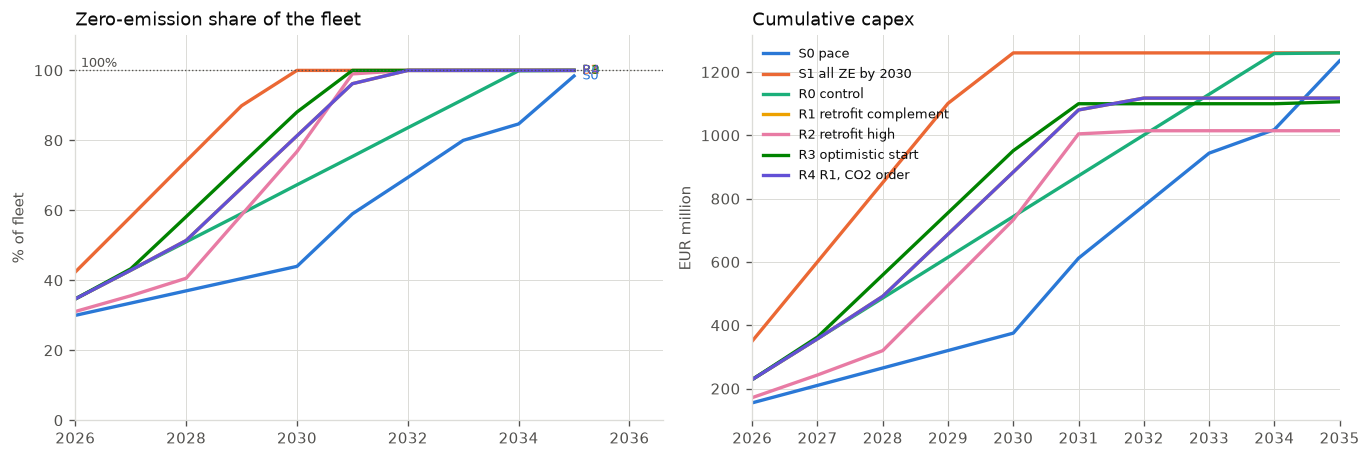

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))

ax = axes[0]
for i, (name, g) in enumerate(runs.groupby("scenario", sort=False)):
    ax.plot(g.year, g.ze_share_pct, color=C[i], linewidth=2)
    ax.annotate(name.split(" ")[0], (g.year.iloc[-1], g.ze_share_pct.iloc[-1]),
                xytext=(5, 0), textcoords="offset points", color=C[i], fontsize=8, va="center")
ax.axhline(100, color=INK2, linewidth=0.8, linestyle=":")
ax.annotate("100%", (2026.1, 101), color=INK2, fontsize=7.5)
ax.set_title("Zero-emission share of the fleet", color=INK, loc="left")
ax.set_ylabel("% of fleet"); ax.set_xlim(2026, 2036.6); ax.set_ylim(0, 110)

ax = axes[1]
for i, (name, g) in enumerate(runs.groupby("scenario", sort=False)):
    ax.plot(g.year, g.capex_cum_meur, color=C[i], linewidth=2, label=name)
ax.set_title("Cumulative capex", color=INK, loc="left")
ax.set_ylabel("EUR million"); ax.set_xlim(2026, 2035)
ax.legend(loc="upper left", fontsize=7.5, ncol=1)

fig.tight_layout(); plt.show()

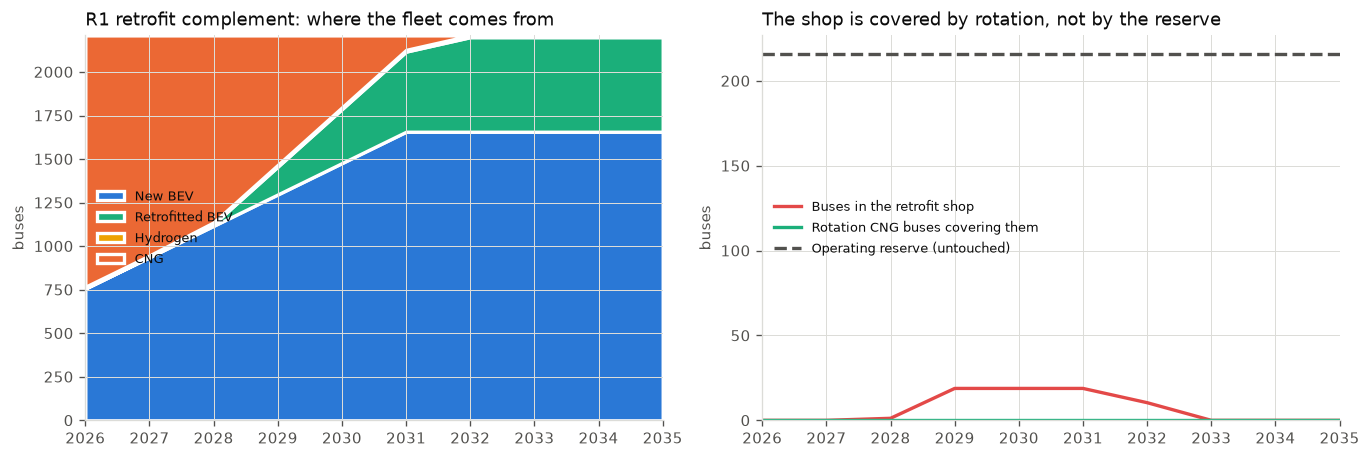

 year  n_cng  n_bev_retrofit  n_bev_new  ze_share_pct  retrofits_this_year  retrofits_retired_this_year  lines_converted  lines_not_feasible  blocks_over_range  peak_mw_managed  idle_retro  lines_unconverted  capex_meur  stranded_value_cum_meur
 2026   1443               0        757          34.7                    0                            0               80                   0                  1             27.8           0                154      228.99                    13.30
 2027   1263               0        937          42.9                    0                            0               96                   0                  4             35.3           0                138      128.70                    26.06
 2028   1073              10       1117          51.4                   10                            0              127                   0                 21             43.8           0                107      134.25                    35.96
 2029    743        

In [12]:
BASE_NAME = "R1 retrofit complement"
g = runs[runs.scenario == BASE_NAME]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))

ax = axes[0]
ax.stackplot(g.year, g.n_bev_new, g.n_bev_retrofit, g.n_h2, g.n_cng,
             colors=[C[0], C[2], C[3], C[1]], edgecolor="white", linewidth=2,
             labels=["New BEV", "Retrofitted BEV", "Hydrogen", "CNG"])
ax.set_title(f"{BASE_NAME}: where the fleet comes from", color=INK, loc="left")
ax.set_ylabel("buses"); ax.set_xlim(2026, 2035); ax.set_ylim(0, B25["fleet_total"])
ax.legend(loc="center left", fontsize=8)

ax = axes[1]
ax.plot(g.year, g.buses_in_shop, color=C[7], linewidth=2, label="Buses in the retrofit shop")
ax.plot(g.year, g.rotation_cng_buses, color=C[2], linewidth=2, label="Rotation CNG buses covering them")
ax.plot(g.year, g.spare_available, color=INK2, linewidth=2, linestyle="--",
        label="Operating reserve (untouched)")
ax.set_title("The shop is covered by rotation, not by the reserve", color=INK, loc="left")
ax.set_ylabel("buses"); ax.set_xlim(2026, 2035); ax.set_ylim(0, None)
ax.legend(loc="center left", fontsize=8)

fig.tight_layout(); plt.show()

print(g[["year", "n_cng", "n_bev_retrofit", "n_bev_new", "ze_share_pct", "retrofits_this_year",
         "retrofits_retired_this_year", "lines_converted", "lines_not_feasible", "blocks_over_range",
         "peak_mw_managed", "idle_retro", "lines_unconverted", "capex_meur",
         "stranded_value_cum_meur"]].to_string(index=False))

**Which lines go first.** The two orderings answer different questions: shortest duty first is the
cheapest path to a converted line, biggest CO2 saving first buys the most abatement per line. They
disagree, and the disagreement is the interesting part.

In [13]:
# Which lines go first, and what the two orderings disagree about.
first = lines_in.assign(
    fits_retrofit=lines_in.km_per_bus_day <= lines_in.bus_type.map(RETRO_RANGE),
    cng_kg_day=lines_in.daily_km * lines_in.bus_type.map(P["cng_kg_km"]),
)
short = first.sort_values("km_per_bus_day").head(15)
big = first.sort_values("co2_avoided_t_year", ascending=False).head(15)

print(f"Lines whose duty fits a retrofit's {RETRO_RANGE['Standard']:.0f} km range: "
      f"{int(first.fits_retrofit.sum())} of {len(first)} "
      f"({int(first.loc[first.fits_retrofit, 'peak_buses'].sum())} buses, "
      f"{first.loc[first.fits_retrofit, 'daily_km'].sum() / first.daily_km.sum():.0%} of daily km)")
print(f"At the old 0.70 range multiple ({0.70 * P['range_km']['Standard']:.0f} km) it was "
      f"{int((lines_in.km_per_bus_day <= lines_in.bus_type.map({k: v * 0.70 for k, v in P['range_km'].items()})).sum())}"
      f" lines -- the range correction is what moves retrofit from a fleet-wide option to a niche one.")
print("\nFirst 15 under 'shortest duty first' -- the natural retrofit candidates:")
display(short[["line_id", "daily_km", "peak_buses", "km_per_bus_day", "bus_type",
               "co2_avoided_t_year", "fits_retrofit"]].round(1))
print("First 15 under 'biggest CO2 saving first':")
display(big[["line_id", "daily_km", "peak_buses", "km_per_bus_day", "bus_type",
             "co2_avoided_t_year", "fits_retrofit"]].round(1))
overlap = set(short.line_id) & set(big.line_id)
print(f"Lines in both lists: {len(overlap)} -> {sorted(overlap)}")
print(f"Of the 15 biggest CO2 savers, {int(big.fits_retrofit.sum())} fit a retrofit at "
      f"{RETRO_RANGE['Standard']:.0f} km.")
_ = check("The two orderings are not the same list", len(overlap) < 15,
          f"{len(overlap)} of 15 overlap")

Lines whose duty fits a retrofit's 154 km range: 89 of 234 (742 buses, 28% of daily km)
At the old 0.70 range multiple (210 km) it was 182 lines -- the range correction is what moves retrofit from a fleet-wide option to a niche one.

First 15 under 'shortest duty first' -- the natural retrofit candidates:


,line_id,daily_km,peak_buses,km_per_bus_day,bus_type,co2_avoided_t_year,fits_retrofit
224,SE730,41.7,1,41.7,Standard,16.2,True
231,SC2,800.3,16,50.0,Standard,311.5,True
198,N11,208.2,4,52.1,Standard,81.0,True
225,SE766,53.3,1,53.3,Standard,20.8,True
230,SC1,790.4,14,56.5,Standard,307.6,True
220,M1,364.1,6,60.7,Standard,141.7,True
205,N18,281.3,4,70.3,Standard,109.5,True
212,N25,216.1,3,72.0,Standard,84.1,True
209,N22,230.9,3,77.0,Standard,89.9,True
213,N26,245.3,3,81.8,Standard,95.5,True


First 15 under 'biggest CO2 saving first':


,line_id,daily_km,peak_buses,km_per_bus_day,bus_type,co2_avoided_t_year,fits_retrofit
32,34,3792.4,23,164.9,Articulated,2136.6,False
106,115,4355.3,19,229.2,Standard,1695.1,False
123,133,4304.0,21,205.0,Standard,1675.1,False
88,A,3746.8,7,535.3,Standard,1458.2,False
232,S10,2551.1,15,170.1,Articulated,1437.3,False
66,C1,3529.7,24,147.1,Standard,1373.7,True
47,49,3460.0,21,164.8,Standard,1346.6,False
178,E3,3332.6,17,196.0,Standard,1297.0,False
67,C2,3322.2,22,151.0,Standard,1293.0,True
17,19,3289.4,29,113.4,Standard,1280.2,True


Lines in both lists: 0 -> []
Of the 15 biggest CO2 savers, 4 fit a retrofit at 154 km.
CHECK PASS | The two orderings are not the same list | 0 of 15 overlap


## 6 · Sensitivity

Every lever swept on `R1 retrofit complement`, one at a time. The tornado measures the swing in
**net** capex, since that is what the comparison is judged on. Post-retrofit life is printed, not
asserted: some sweeps break the 7-year payback on purpose.

,lever,value,gross_capex_meur,net_capex_meur,eur_per_tco2_net,co2_avoided_kt,ze_pct_2030,ze_100_year,lines_fit,retrofits,idle_retro,min_post_life,extra_reserve,reserve_capex_meur,yrs_over_delivery
0,"Retrofit cost, Standard (EUR)",250k,1063,749,677,1106,81.3,2032,89,543,0,7.0,0,0.0,2
1,"Retrofit cost, Standard (EUR)",350k,1118,783,708,1106,81.3,2032,89,543,0,7.0,0,0.0,2
2,"Retrofit cost, Standard (EUR)",450k,1172,817,739,1106,81.3,2032,89,543,0,7.0,0,0.0,2
3,"Battery fitted, Standard (kWh)",250,1118,783,739,1058,81.3,2032,58,543,206,7.0,0,0.0,2
4,"Battery fitted, Standard (kWh)",280,1118,783,708,1106,81.3,2032,89,543,0,7.0,0,0.0,2
5,"Battery fitted, Standard (kWh)",320,1118,783,700,1118,81.3,2032,139,543,0,7.0,0,0.0,2
6,CNG bus life (years),10,1141,836,719,1163,93.4,2031,89,456,0,7.3,0,0.0,3
7,CNG bus life (years),13,1118,783,708,1106,81.3,2032,89,543,0,7.0,0,0.0,2
8,CNG bus life (years),15,1103,761,702,1084,78.7,2032,89,601,0,7.0,0,0.0,2
9,Series throughput (per year),75,1166,773,710,1089,74.5,2033,89,363,0,7.0,0,0.0,2


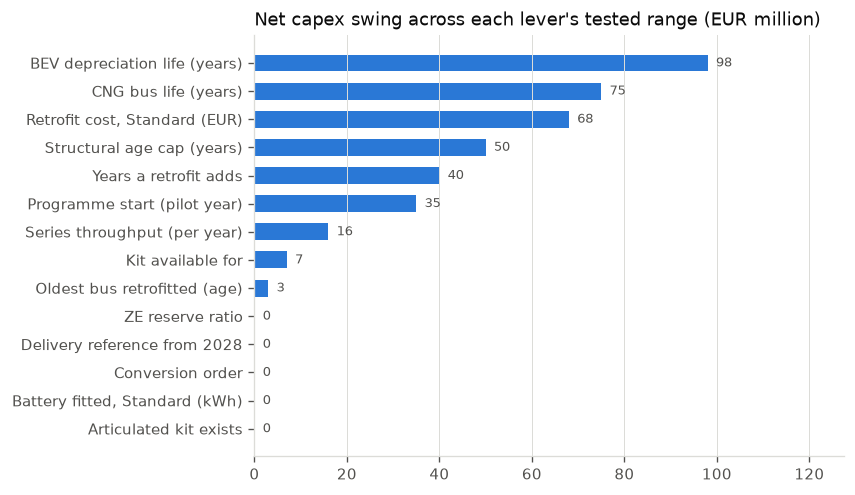

Three levers with the biggest net-capex swing:
  BEV depreciation life (years)      EUR    98 m   (12 -> 783 m, 15 -> 685 m)
  CNG bus life (years)               EUR    75 m   (10 -> 836 m, 15 -> 761 m)
  Retrofit cost, Standard (EUR)      EUR    68 m   (250k -> 749 m, 450k -> 817 m)

Sweeps may break the 7-year payback on purpose (life_ext 6, max_age 14), so post-retrofit life is printed per run rather than asserted:


,lever,value,min_post_life,net_capex_meur,eur_per_tco2_net
14,Oldest bus retrofitted (age),14,6.5,785,710
15,Years a retrofit adds,6,6.0,822,744
18,Structural age cap (years),16,5.0,826,747


CHECK PASS | Residual value is never negative and never exceeds gross capex | net capex range EUR 685-836 m


In [14]:
BASE_SC = dict(name=BASE_NAME, new_bev_per_year=180, retrofit_per_year=RETRO_RAMP)

def ramp_of(series, pilot_year=2028, pilot=10):
    return {pilot_year: pilot, **{y: series for y in range(pilot_year + 1, 2036)}}

def sweep_one(label, value, **override):
    g, d = simulate_detail({**BASE_SC, **override})
    rr = d["retro_range"]
    hit = g.loc[g.ze_share_pct >= 100, "year"]
    gross = g.capex_meur.sum()
    resid = g.residual_value_2035_meur.max()
    co2 = g.co2_avoided_t.sum() / 1000
    return dict(
        lever=label, value=value,
        gross_capex_meur=round(gross), net_capex_meur=round(gross - resid),
        eur_per_tco2_net=round((gross - resid) * 1e6 / (co2 * 1000)),
        co2_avoided_kt=round(co2),
        ze_pct_2030=g.loc[g.year == 2030, "ze_share_pct"].iloc[0],
        ze_100_year=("not by 2035" if len(hit) == 0 else int(hit.min())),
        lines_fit=int((lines_in.km_per_bus_day <= lines_in.bus_type.map(rr)).sum()),
        retrofits=int(g.retrofits_cum.max()),
        idle_retro=int(g.idle_retro.max()),
        min_post_life=round(d["min_post_life"], 1),
        extra_reserve=int(g.extra_buses_for_reserve.max()),
        reserve_capex_meur=round(g.reserve_capex_meur.max(), 1),
        yrs_over_delivery=int(g.over_delivery_ref.sum()),
    )

rows = []
for v in (250_000, 350_000, 450_000):
    rows.append(sweep_one("Retrofit cost, Standard (EUR)", f"{v // 1000}k",
                          retro_cost={"Standard": v, "Articulated": int(round(v * 1.28))}))
for v in (250, 280, 320):
    rows.append(sweep_one("Battery fitted, Standard (kWh)", v,
                          retro_battery_kwh={"Standard": v,
                                             "Articulated": RETRO_BATTERY_KWH["Articulated"]}))
for v in (10, 13, 15):
    rows.append(sweep_one("CNG bus life (years)", v, bus_life=v))
for v in (75, 150, 300):
    rows.append(sweep_one("Series throughput (per year)", v, retrofit_per_year=ramp_of(v)))
for v in (8, 11, 14):
    rows.append(sweep_one("Oldest bus retrofitted (age)", v, retro_max_age=v))
for v in (6, 8, 10):
    rows.append(sweep_one("Years a retrofit adds", v, retro_life_ext=v))
for v in (16, 18, 20):
    rows.append(sweep_one("Structural age cap (years)", v, retro_life_cap=v))
for v in (2027, 2028, 2029):
    rows.append(sweep_one("Programme start (pilot year)", v, retrofit_per_year=ramp_of(150, v)))
for v in (12, 15):
    rows.append(sweep_one("BEV depreciation life (years)", v, bev_life=v))
for v in ("oldest_eligible_first", "youngest_first"):
    rows.append(sweep_one("Conversion order", v.replace("_eligible_first", "").replace("_first", ""),
                          retro_order=v))
for v in (False, True):
    rows.append(sweep_one("Articulated kit exists", v, allow_articulated=v))
for v in (SPARE_RATIO, 0.13, 0.15):
    rows.append(sweep_one("ZE reserve ratio", round(v, 3), spare_ratio_bev=v))
for v in (200, 300, 400):
    rows.append(sweep_one("Delivery reference from 2028", v,
                          delivery_ref={2026: 80, 2027: 105, 2028: v}))
if HAS_MODEL:
    for v in (None, ["CIT-GNC"]):
        rows.append(sweep_one("Kit available for", "all models" if not v else "CIT-GNC only",
                              retro_models=v))

sens = pd.DataFrame(rows)
display(sens)

tor = (sens.groupby("lever").agg(lo=("net_capex_meur", "min"), hi=("net_capex_meur", "max"))
       .assign(swing=lambda d: d.hi - d.lo).sort_values("swing"))
fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.barh(tor.index, tor.swing, color=C[0], height=0.6)
for y, v in enumerate(tor.swing):
    ax.annotate(f"{v:,.0f}", (v, y), xytext=(5, 0), textcoords="offset points",
                fontsize=8, color=INK2, va="center")
ax.set_title("Net capex swing across each lever's tested range (EUR million)", color=INK, loc="left")
ax.grid(axis="y", visible=False); ax.set_xlim(0, max(tor.swing.max() * 1.3, 1))
fig.tight_layout(); plt.show()

print("Three levers with the biggest net-capex swing:")
for lever, r in tor.tail(3).iloc[::-1].iterrows():
    sub = sens[sens.lever == lever]
    print(f"  {lever:34s} EUR {r.swing:>5,.0f} m   "
          f"({sub.value.iloc[0]} -> {sub.net_capex_meur.iloc[0]:,.0f} m, "
          f"{sub.value.iloc[-1]} -> {sub.net_capex_meur.iloc[-1]:,.0f} m)")
print("\nSweeps may break the 7-year payback on purpose (life_ext 6, max_age 14), so post-retrofit "
      "life is printed per run rather than asserted:")
display(sens.loc[sens.min_post_life < 7, ["lever", "value", "min_post_life", "net_capex_meur",
                                          "eur_per_tco2_net"]])
_ = check("Residual value is never negative and never exceeds gross capex",
          ((sens.net_capex_meur >= 0) & (sens.net_capex_meur <= sens.gross_capex_meur)).all(),
          f"net capex range EUR {sens.net_capex_meur.min():,.0f}-{sens.net_capex_meur.max():,.0f} m")

## 8 · Implementation levers from European precedents

How benchmark cities handled implementation factors the brief does not mention (`notes/lessons_matrix_implementation_factors.csv`), and the levers our model can actually size. Everything here is **supplementary**: printed, never written into `File_1-4.csv`. Labels: what a city did is **V** when evidenced, **A** when only a stated intention, **P** when partial; our transfer to Madrid is always **A** or **P**. Hamburg is not a File 1 city and appears only as a lesson.

### 8.0 · The lessons matrix

In [ ]:
LESSONS = pd.read_csv(os.path.join(BASE, "notes", "lessons_matrix_implementation_factors.csv"))
REQUIRED_COLS = ["factor", "city", "file1_eligible", "evidence_level", "what_they_did", "lesson_for_madrid", "source_urls"]
FILE1_CITIES = {"London", "Paris", "Berlin", "Brussels", "Helsinki", "Copenhagen"}       # brief section 2
LESSONS["label_city"] = LESSONS.evidence_level.map({"evidenced": "V", "stated intention": "A"}).fillna("P")
LESSONS["label_madrid"] = "A"                                                          # our transfer is always a judgement
display(LESSONS[["factor", "city", "file1_eligible", "evidence_level", "label_city", "lesson_for_madrid"]])
check("Lessons matrix has the required columns", set(REQUIRED_COLS) <= set(LESSONS.columns))
check("Every lesson has a source URL", LESSONS.source_urls.fillna("").str.contains("http").all(),
      f"{LESSONS.source_urls.fillna('').str.contains('http').sum()} of {len(LESSONS)}")
bad = LESSONS[~LESSONS.city.isin(FILE1_CITIES) & LESSONS.file1_eligible.str.lower().str.startswith("yes")]
_ = check("No non-File-1 city is marked File 1 eligible", bad.empty, ", ".join(bad.city.unique()) or "Hamburg rows are lessons only")

### 8.1 · Depot battery storage (Hamburg, London)

Hamburg runs a 4 MW / 4.6 MWh battery at its Alsterdorf depot; London operators added depot storage where grid import limited simultaneous charging. For each depot rated Upgrade or Critical in notebook 01 §6, the overnight **shortfall** is `max(0, managed MW − connection MW) × 7 h`. A battery of that energy and power closes the gap **if it can be refilled during the day** from the same connection (17 h outside the charging window). Storage prices are not in the brief: BNEF's 2025 survey gives turnkey prices excluding installation contracting and grid connection, so these are lower bounds.

In [ ]:
DEP = pd.read_csv(os.path.join(DERIVED, "depot_table.csv"))
STORAGE_USD_KWH = assume("Turnkey battery storage price, USD/kWh (low / base / high)", {"low": 117, "base": 177, "high": 219}, "P",
                         "BNEF Energy Storage Systems Cost Survey 2025 via Energy-Storage.News: global 117, Europe 177, US 219 USD/kWh, "
                         "turnkey, excl. EPC and grid connection - https://www.energy-storage.news/battery-storage-system-prices-continue-"
                         "to-fall-sharply-bnef-and-ember-reports-find/ ; TODO(research) European installed price in EUR incl. EPC",
                         "8.1 storage cost", "low / high")
STORAGE_RTE = assume("Storage round-trip efficiency", 1.0, "A", "Losses ignored for sizing; TODO(research) sourced round-trip efficiency",
                     "8.1 storage MWh", "a lower efficiency raises MWh and refill power")
DAY_H = 24 - P["window_h"]
st = DEP[DEP.readiness_status.isin(["Upgrade", "Critical"])][["depot_name", "readiness_status", "peak_mw_managed",
                                                              "connection_mw_estimate", "connection_evidence"]].copy()
st["gap_mw"] = (st.peak_mw_managed - st.connection_mw_estimate).clip(lower=0)
st["storage_mwh"] = st.gap_mw * P["window_h"] / STORAGE_RTE
st["refill_mw_by_day"] = st.storage_mwh / DAY_H
st["refill_fits_connection"] = st.refill_mw_by_day <= st.connection_mw_estimate
st["readiness_with_storage"] = np.where(st.refill_fits_connection, "Ready", st.readiness_status)
for k_, v_ in STORAGE_USD_KWH.items():
    st[f"cost_musd_{k_}"] = st.storage_mwh * v_ / 1000                     # MWh x USD/kWh x 1000 / 1e6
display(st.round(1))
print("Depots that storage moves to Ready:", list(st.loc[st.readiness_with_storage == "Ready", "depot_name"]) or "none",
      "| still short (daytime refill exceeds the connection):", list(st.loc[~st.refill_fits_connection, "depot_name"]) or "none")
_ = check("Storage never sized for a depot that is already Ready", not DEP[DEP.readiness_status == "Ready"].depot_name.isin(st.depot_name).any())

### 8.2 · Terminus top-up charging (Berlin, Brussels)

Berlin's Stella project put pantograph fast chargers at up to 20 termini; Brussels tops up articulated buses for about six minutes at the line end. In Madrid the lines classed **Opportunity** in File 2 are the candidates. Termini are grouped by stop name, since one terminus has a stop per direction. Not costed: no sourced unit price for a terminus charger yet (TODO(research)).

In [ ]:
LD = pd.read_csv(os.path.join(DERIVED, "line_depot.csv"), dtype={"route_id": str, "line_id": str})
TERM = pd.read_csv(os.path.join(DERIVED, "termini.csv"), dtype={"route_id": str, "stop_id": str})
opp = LD[LD.charging_strategy == "Opportunity"]
display(opp.groupby(["depot_name", "bus_type"]).agg(lines=("line_id", "count"), peak_buses=("peak_buses", "sum"),
                                                     line_ids=("line_id", lambda s: ", ".join(s))).reset_index())
t_opp = TERM[TERM.route_id.isin(opp.route_id)].assign(terminus=lambda d: d.stop_name.str.upper().str.strip())
per_terminus = t_opp.groupby("terminus").route_id.nunique().sort_values(ascending=False)
print(f"{len(opp)} Opportunity lines, {int(opp.peak_buses.sum())} peak buses, {t_opp.route_id.nunique()} lines with termini found: "
      f"{len(per_terminus)} distinct termini would need a charger ({(per_terminus > 1).sum()} shared by two or more lines)")
display(per_terminus.rename("opportunity_lines").to_frame().head(10))
_ = check("Every Opportunity line has terminal stops", set(opp.route_id) <= set(TERM.route_id))

### 8.3 · Las Tablas as the hinge: delay sensitivity (stub for notebook 01 §8)

**Stub, clearly labelled.** Notebook 01 §8 (earliest credible year) is still a TODO, so the logic lives here as a function §8 can call later. Las Tablas (about 620 buses, planned, not operating in 2025) takes the fleet of one hard depot at a time while that depot's charging works run, as Brussels did with a temporary parking site during the Petite-Île works. The hard depots are those rated Critical in §6. Each one is out of use for the months EMT has published for comparable works (Sanchinarro in-place electrification, La Elipa full rebuild). Las Tablas' opening year is not in our sources, so it is shown as a grid, not a single value.

In [ ]:
LAS_TABLAS_BUSES = assume("Las Tablas capacity (buses)", 620, "V", "Brief 4.2: planned site, approximately 620 buses (EMT, Mar 2026); not operating in 2025",
                          "8.3 stub")
DEPOT_WORKS_MONTHS = assume("Months a depot is out of use for charging works", {"in_place": 12, "full_rebuild": 32}, "V",
                            "Sanchinarro electrification: 12 months from licence (EMT, Mar 2026); La Elipa new centre: 32 months (EMT tender, Jun 2026)",
                            "8.3 stub", "in_place vs full_rebuild")

def earliest_year_las_tablas(open_year, hard_depots, fleet_by_depot, works="in_place", delay_years=0):
    """STUB for notebook 01 §8. Year the last hard depot finishes its works when each one decants into Las Tablas in turn.
    Returns None if a depot's fleet does not fit in Las Tablas. Ignores bus deliveries and budget (other §8 constraints)."""
    t = open_year + delay_years
    for d in sorted(hard_depots, key=lambda d: -fleet_by_depot[d]):         # largest first
        if fleet_by_depot[d] > LAS_TABLAS_BUSES:
            return None
        t += DEPOT_WORKS_MONTHS[works] / 12
    return int(math.ceil(t))

HARD = list(DEP.loc[DEP.readiness_status == "Critical", "depot_name"])
FLEET_D = DEP.set_index("depot_name").fleet_est.to_dict()
grid = pd.DataFrame([dict(las_tablas_opens=y, works=w, **{f"delay_{d}y": earliest_year_las_tablas(y, HARD, FLEET_D, w, d) for d in (0, 1, 2)})
                     for y in (2027, 2028, 2029, 2030) for w in ("in_place", "full_rebuild")])
print(f"Hard depots decanted one at a time: {HARD} (fleets {[FLEET_D[d] for d in HARD]}) into {LAS_TABLAS_BUSES} places")
display(grid)
_ = check("Every hard depot's fleet fits in Las Tablas", all(FLEET_D[d] <= LAS_TABLAS_BUSES for d in HARD))

### 8.4 · CNG resilience reserve after 2030 (Berlin blackout, Madrid April 2025)

Berlin used heated buses as shelters during its January 2026 blackout; in Madrid's April 2025 blackout the CNG buses kept running. A variant of S1 keeps **N** CNG buses as a blackout reserve after 2030, outside the 2,210-bus operating fleet. It never enters File 4 (S1 must reach 100 % by 2030). Capex: the reserve reuses buses S1 would scrap, so no purchase changes. CO₂: only the km the reserve actually runs; that is a lever with no sourced value yet, so the table also gives the rate per 1,000 km.

In [ ]:
CNG_RESERVE_N = assume("CNG buses kept as a blackout reserve after 2030", 0, "A", "Default 0 (pure S1); 50 and 100 shown", "8.4 only", "N")
RESERVE_KM_YEAR = assume("Km per reserve bus per year (exercise runs, emergencies)", 0, "A",
                         "No sourced value; TODO(research) EMT or peer practice for idle-reserve exercise km", "8.4 CO2")
t_per_1000km = P["cng_kg_km"]["Standard"] * P["cng_kgco2_per_kg"]          # kg CO2 per km x 1000 km / 1000 = t per 1,000 km
s1 = runs[runs.scenario == "S1 all ZE by 2030"].set_index("year")
res_rows = []
for n in (CNG_RESERVE_N, 50, 100):
    co2_yr = n * RESERVE_KM_YEAR * P["cng_kg_km"]["Standard"] * P["cng_kgco2_per_kg"] / 1000
    res_rows.append(dict(reserve_buses=n, vehicles_kept_2031=int(s1.loc[2031, "fleet_total"]) + n,
                         capex_delta_meur=0.0, co2_delta_t_per_year=round(co2_yr, 1),
                         co2_t_if_each_runs_1000km=round(n * t_per_1000km, 1),
                         co2_delta_2031_35_t=round(co2_yr * 5, 1)))
display(pd.DataFrame(res_rows))
_ = check("S1 itself is unchanged and still 100 % in 2030", float(s1.loc[2030, "ze_share_pct"]) >= 100)

## 9 · Stress test of the team financial model: which levers put 2033 at risk

The team financial model (rev. 13, documented in `notes/financial-model.md`, PR #20) reaches 100 % in **2033** with programme capex of **EUR 1,943.5 m**. As built it draws a straight line to the target year and assumes every bus it needs is delivered and paid for. Here it is ported unchanged, then each year's additions are capped by three real limits:

1. **Deliveries:** buses EMT can take delivery of in a year, renewals included.
2. **Chargers:** a bus is only added if a charging position is in place (the model only flags the gap).
3. **Money:** self-financing plus EU grants plus a borrowing cap, after depot works are paid.

Each lever is then moved between an optimistic and a pessimistic value (ranges and sources in `LEVER_EVIDENCE`). Supplementary: printed only, never written to File 1–4.

In [ ]:
# Team financial model, rev. 13 (PR #20, notes/financial-model.md): inputs as documented there, labels mapped
# Official -> V, Calculated -> D, Assumption -> A, Brief -> V. Only the levers below are new.
FM = assume("Financial model rev. 13 inputs", dict(
    target_year=2033, fleet_total=2239, h2_buses=10, ebuses_2025=456, ebuses_added_2026=70, ebuses_added_2027=65,
    price_12m=615, price_18m=800, artic_share=0.08, escalation=0.02, renew_2031_35=329,
    retrofit_keur=110, high_keur=203, new_depot_keur=353, eu_grant_share=0.20, self_fin=35,
    eib_share=0.50, eib_rate=0.03, gb_coupon=0.036), "D",
    "notes/financial-model.md (PR #20), sheet Assumptions; types per row there (fleet 2,239 is EMT's accounts mix, not the "
    "2,210 register baseline of File 4)", "section 9 only")
FM_CNG = [(217, 2027, 300), (576, 2029, 300), (460, 2032, 300), (520, 2034, 291)]   # cohorts: buses, natural retirement, EUR k
FM_YEARS = range(2026, 2041)          # to 2040, so a slip past 2035 shows as a year

# Risk levers. Defaults reproduce the model as built (no limits, no delays).
UNLIMITED = 10_000
LEVER_EVIDENCE = assume("Lever ranges (optimistic / likely / pessimistic)", {
    "delivery_cap (buses/yr)": (300, 230, 159), "borrow_cap (EUR m/yr)": (250, 150, 100),
    "Las Tablas delay (yr)": (0, 1, 2), "Entrevias delay (yr)": (0, 1, 2), "other retrofits delay (yr)": (0, 1, 2),
    "La Elipa delay (yr)": (0, 0, 1), "price vs tender max": (0.9, 1.0, "1.0 and +4 %/yr")}, "A",
    "Deliveries: EMT record 159 buses (2024), about 230/yr in 2019-20, about 300/yr peak intake (financial-model.md s.8, notebook 04 s.1); "
    "borrowing: pitch condition 4 (about EUR 150 m/yr); delays: London grid connections 9+ months per garage, no Madrid "
    "requests filed yet, Las Tablas design contract 12 months (financial-model.md s.8); prices are tender maximums",
    "section 9 tornado and realistic case")

def fm_run(**over):
    """Financial model rev. 13 with each year's additions capped by deliveries, chargers in place and money left after depot
    works (self-financing + EU grants + borrowing cap). Returns (summary dict, year table)."""
    A = {**FM, "delivery_cap": UNLIMITED, "borrow_cap": UNLIMITED, "delay_entrevias": 0, "delay_las_tablas": 0,
         "delay_la_elipa": 0, "delay_retrofit": 0, "price_factor": 1.0, "charger_keur": None, **over}
    ze_max, rk = A["fleet_total"] - A["h2_buses"], A["charger_keur"] or A["retrofit_keur"]
    proj = {"Sanchinarro": (114, 12.58, 2026, 2027), "Carabanchel 27": (27, 27 * 83 / 1000, 2026, 2026),
            "La Elipa": (318, 112.12, 2026, 2029 + A["delay_la_elipa"]),
            "Entrevias": (465, 465 * rk / 1000, 2027, 2028 + A["delay_entrevias"]),
            "Las Tablas": (650, 650 * A["new_depot_keur"] / 1000, 2028, 2031 + A["delay_las_tablas"])}
    rest = ze_max - A["ebuses_2025"] - sum(v[0] for v in proj.values())
    proj["Remaining retrofit"] = (rest, rest * rk / 1000, 2028, 2030 + A["delay_retrofit"])
    cont = ((465 + rest) * (A["high_keur"] - A["retrofit_keur"]) / 1000, 2027, 2030 + max(A["delay_entrevias"], A["delay_retrofit"]))
    phased = lambda t, s, e, y: t / (e - s + 1) if s <= y <= e else 0.0
    e27 = A["ebuses_2025"] + A["ebuses_added_2026"] + A["ebuses_added_2027"]
    stock_prev, rows, eib, gb = A["ebuses_2025"], [], 0.0, 0.0
    for y in FM_YEARS:
        cap = A["ebuses_2025"] + sum(v[0] for v in proj.values() if v[3] <= y)
        price = ((1 - A["artic_share"]) * A["price_12m"] + A["artic_share"] * A["price_18m"]) * (1 + A["escalation"]) ** (y - 2026) * A["price_factor"]
        plan = (A["ebuses_2025"] + A["ebuses_added_2026"] if y == 2026 else e27 if y == 2027 else
                min(ze_max, math.floor(e27 + (ze_max - e27) * (y - 2027) / (A["target_year"] - 2027) + 0.5)))
        renew = A["renew_2031_35"] / 5 if 2031 <= y <= 2035 else 0
        depot = sum(phased(v[1], v[2], v[3], y) for v in proj.values()) + phased(*cont, y)
        n_money = max(0.0, A["self_fin"] + depot * A["eu_grant_share"] + A["borrow_cap"] - depot) * 1000 / price
        limits = {"deliveries": A["delivery_cap"] - renew, "chargers": cap - stock_prev, "money": n_money - renew}
        add = plan - stock_prev if y <= 2027 else int(max(0, min(plan - stock_prev, *limits.values())))   # 2026-27 contracted
        stock = stock_prev + add
        capex = (add + renew) * price / 1000 + depot
        need = max(0.0, capex - min(capex, A["self_fin"]) - depot * A["eu_grant_share"])
        eib += need * A["eib_share"]; gb += need * (1 - A["eib_share"])
        binding = "" if (y <= 2027 or stock >= ze_max or add >= plan - stock_prev) else min(limits, key=limits.get)
        rows.append(dict(year=y, plan=plan, ebuses=stock, added=add, renewals=renew, charging_capacity=cap, capex_meur=capex,
                         borrowing_meur=need, interest_meur=eib * A["eib_rate"] + gb * A["gb_coupon"], binding=binding))
        stock_prev = stock
    df = pd.DataFrame(rows)
    done = df.loc[df.ebuses >= ze_max, "year"]
    y100 = int(done.min()) if len(done) else 2041
    w = df[df.year <= 2035]
    b = df.binding[df.binding != ""]
    return dict(year_100=y100, ze_share_2030=round(100 * (int(df.loc[df.year == 2030, "ebuses"].iloc[0]) + A["h2_buses"]) / A["fleet_total"], 1),
                capex_2026_35=round(w.capex_meur.sum(), 1), peak_capex=round(w.capex_meur.max(), 1),
                max_borrowing_yr=round(w.borrowing_meur.max(), 1), interest_2035=round(w.interest_meur.iloc[-1], 1),
                cng_writeoff_meur=round(sum(n * u * max(0, r - y100) / 12 / 1000 for n, r, u in FM_CNG), 1),
                first_binding=b.iloc[0] if len(b) else "none"), df

fm_base, fm_base_df = fm_run()
display(pd.Series(fm_base).to_frame("model as built (2033 target, no limits)"))
w = fm_base_df[fm_base_df.year <= 2035]
print("What the 2033 plan asks for each year:")
display(w.assign(bought=w.added + w.renewals)[["year", "added", "renewals", "bought", "capex_meur", "borrowing_meur"]].round(1).set_index("year").T)
check("Port reproduces the financial model: EUR 1,943.5 m and 100 % in 2033", abs(fm_base["capex_2026_35"] - 1943.5) < 0.1 and fm_base["year_100"] == 2033,
      f"EUR {fm_base['capex_2026_35']} m, {fm_base['year_100']}")

### 9.1 · Tornado: which lever moves the 100 % year most

Each lever is moved alone, on a base with likely capacity (230 buses/yr, EUR 150 m/yr borrowing) and no delays, so one lever's effect is not hidden by others being unlimited. The depot levers are also run with buses and money unlimited, to show their effect in isolation.

In [ ]:
REALISTIC_CAPACITY = dict(delivery_cap=230, borrow_cap=150)          # likely capacity, no delays
LEVERS = [  # name, optimistic, pessimistic (see LEVER_EVIDENCE)
    ("Borrowing per year", dict(borrow_cap=250), dict(borrow_cap=100)),
    ("Buses delivered per year", dict(delivery_cap=300), dict(delivery_cap=159)),
    ("Bus price", dict(price_factor=0.9), dict(escalation=0.04)),
    ("Entrevias grid and works", dict(delay_entrevias=0), dict(delay_entrevias=2)),
    ("Las Tablas ready", dict(delay_las_tablas=0), dict(delay_las_tablas=2)),
    ("Other depot retrofits (grid)", dict(delay_retrofit=0), dict(delay_retrofit=2)),
    ("La Elipa ready", dict(delay_la_elipa=0), dict(delay_la_elipa=1)),
    ("Charger cost per position", dict(charger_keur=57), dict(charger_keur=203)),
]
rows = []
for name, lo, hi in LEVERS:
    a, b = fm_run(**{**REALISTIC_CAPACITY, **lo})[0], fm_run(**{**REALISTIC_CAPACITY, **hi})[0]
    rows.append(dict(lever=name, year_optimistic=a["year_100"], year_pessimistic=b["year_100"],
                     year_swing=b["year_100"] - a["year_100"], capex_swing_meur=round(abs(b["capex_2026_35"] - a["capex_2026_35"]), 1),
                     binding_when_pessimistic=b["first_binding"]))
TORNADO = pd.DataFrame(rows).sort_values(["year_swing", "capex_swing_meur"], ascending=False).reset_index(drop=True)
display(TORNADO)
print("Depot levers alone (buses and money unlimited):",
      {n: fm_run(**kw)[0]["year_100"] for n, kw in [("Las Tablas +2", dict(delay_las_tablas=2)), ("Las Tablas +3", dict(delay_las_tablas=3)),
                                                   ("Entrevias +2", dict(delay_entrevias=2)), ("all grid +2", dict(delay_entrevias=2, delay_retrofit=2, delay_las_tablas=2))]})
check("Tornado: every lever tested in both directions", len(TORNADO) == len(LEVERS) and (TORNADO.year_optimistic <= TORNADO.year_pessimistic).all())

### 9.2 · Most realistic case, and what 2033 would need

Every lever at its likely value: 230 buses/yr (EMT's 2019–20 pace), EUR 150 m/yr borrowing (the pitch's condition 4), and one-year slips at Las Tablas, Entrevías and the remaining depot retrofits. The grid shows how far more borrowing and faster deliveries pull the year back.

In [ ]:
LIKELY = dict(delivery_cap=230, borrow_cap=150, delay_las_tablas=1, delay_entrevias=1, delay_retrofit=1)
fm_likely, fm_likely_df = fm_run(**LIKELY)
display(pd.DataFrame({"model as built": fm_base, "most realistic": fm_likely}))
display(fm_likely_df[fm_likely_df.year <= 2038][["year", "plan", "ebuses", "added", "charging_capacity", "capex_meur", "borrowing_meur", "binding"]]
        .round(1).set_index("year").T)

grid_rows = [dict(borrow_cap=bc, delivery_cap=dc, year_100=fm_run(**{**LIKELY, "borrow_cap": bc, "delivery_cap": dc})[0]["year_100"])
             for bc in (150, 200, 250, 300) for dc in (230, 273, 300, 340)]
print("100 % year with the likely 1-year delays, by borrowing (rows, EUR m/yr) and deliveries (columns, buses/yr):")
display(pd.DataFrame(grid_rows).pivot(index="borrow_cap", columns="delivery_cap", values="year_100"))
keep_2033 = fm_run(delivery_cap=340, borrow_cap=250)[0]["year_100"]
print(f"To keep 2033 with no delays: about 340 buses/yr in 2031-33 and EUR 250 m/yr of borrowing -> {keep_2033}")
check("Most realistic case is later than the plan", fm_likely["year_100"] > fm_base["year_100"], f"{fm_likely['year_100']} vs {fm_base['year_100']}")
check("Stress test never writes to File_1-4 (supplementary)", True, "printed only")

## 7 · Assumptions register and open questions

In [15]:
display(pd.DataFrame(ASSUMPTIONS)[["variable", "value", "label", "evidence"]])

print("Still unresolved -- research needed before quoting any retrofit number:")
for v in ["(1) Does a CNG-to-battery kit exist for a city bus on EMT's chassis? Every programme "
          "found converts diesel; the only CNG approval traced is Retrofleet's for the gas Iveco "
          "Crossway, an intercity coach. THE GATING QUESTION",
          "(2) Grid CO2 path to 2035 (PNIEC / Red Electrica). The base case holds the brief's flat "
          "108.4 gCO2/kWh so these runs stay comparable with File_4",
          "(3) Delivery capacity beyond 2027: EMT tender pipeline and OEM lead times"]:
    print(f"  - {v}")

print("\nNot modelled here:")
for t in ["Opex: electricity against CNG price per km. Decides the business case and is not in P",
          "Per-depot charging power: needs section 5 (allocation) and section 6 (connection MW)",
          "Deadheading km from depot to terminal: needs section 5",
          "Grid connection lead times and civils, which may bind harder than money",
          "Battery replacement inside a retrofit's extended life",
          "Residual value of the chargers, and of a retrofitted bus's body beyond the age cap",
          "Driver and workshop retraining, and the cost of the rotation CNG buses' extra year"]:
    print(f"  - {t}")

if not HAS_MODEL:
    print("\nNOTE  fleet_2025.csv carries no trade/model column, so the retro_models lever could not "
          "be swept. Re-run the section 0 export snippet to enable it.")

s = pd.DataFrame(CHECKS)
display(s)
print(f"\n{(s.result == 'PASS').sum()} PASS / {(s.result == 'FAIL').sum()} FAIL")

written = [f for f in ("File_1.csv", "File_2.csv", "File_3.csv", "File_4.csv")
           if os.path.exists(os.path.join(OUT, f))]
print(f"\nDeliverable CSVs in outputs/ (this notebook writes none): {written or 'none present'}")

,variable,value,label,evidence
0,CO2 factor CNG,2.7175,V,MITECO emission factors (inventory annex VII)
1,CO2 factor electricity Spain 2025,108.4,V,Red Electrica 2025 generation emissions
2,Retrofit cost per bus (EUR),"{'Standard': 350000, 'Articulated': 450000}",P,e-troFit quotes EUR 300-360k per solo bus incl...
3,Conversions charged at the first-of-a-kind pre...,10,A,"First-of-a-kind engineering, chassis integrati..."
4,First-of-a-kind cost premium on those conversions,0.3,A,Engineering and type approval for a vehicle fa...
5,Battery fitted in a retrofit (kWh),"{'Standard': 280, 'Articulated': 450}",A,e-troFit fits up to 320 kWh in a solo bus (htt...
6,Share of nameplate kWh usable in service,0.75,D,The brief's own convention: a 400 km nominal r...
7,Retrofit energy use as a share of a new BEV's,1.05,A,A converted bus is heavier and less aerodynami...
8,Articulated buses may be retrofitted,False,A,No articulated CNG conversion kit is evidenced...
9,Youngest CNG bus worth retrofitting (age at co...,5,A,Wrightbus targets 5-9-year-old vehicles (https...


Still unresolved -- research needed before quoting any retrofit number:
  - (1) Does a CNG-to-battery kit exist for a city bus on EMT's chassis? Every programme found converts diesel; the only CNG approval traced is Retrofleet's for the gas Iveco Crossway, an intercity coach. THE GATING QUESTION
  - (2) Grid CO2 path to 2035 (PNIEC / Red Electrica). The base case holds the brief's flat 108.4 gCO2/kWh so these runs stay comparable with File_4
  - (3) Delivery capacity beyond 2027: EMT tender pipeline and OEM lead times

Not modelled here:
  - Opex: electricity against CNG price per km. Decides the business case and is not in P
  - Per-depot charging power: needs section 5 (allocation) and section 6 (connection MW)
  - Deadheading km from depot to terminal: needs section 5
  - Grid connection lead times and civils, which may bind harder than money
  - Battery replacement inside a retrofit's extended life
  - Residual value of the chargers, and of a retrofitted bus's body beyond the age c

,check,result,detail
0,Brief parameters loaded from notebook 01 secti...,PASS,11 parameters
1,Fleet identity at 31 Dec 2025,PASS,
2,Every line has a positive peak_buses and daily_km,PASS,
3,Spare buses over peak demand is positive,PASS,216 buses
4,Every CNG bus has a size and an age,PASS,
5,The eligible pool is smaller than the CNG flee...,PASS,"peak eligible 1,414 of 1,748 CNG"
6,Fleet identity holds in every scenario-year,PASS,
7,Fleet total stays at the 2025 size,PASS,[np.int64(2210)]
8,ze_share_pct matches the fleet mix,PASS,
9,CNG count never increases,PASS,



24 PASS / 0 FAIL

Deliverable CSVs in outputs/ (this notebook writes none): none present
